In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [2]:
def parse_cv_metrics(root_dir):
    dfs = []

    for dirpath, _, filenames in os.walk(root_dir):

        if "cv_all_folds_metrics.tsv" not in filenames:
            continue

        filepath = os.path.join(dirpath, "cv_all_folds_metrics.tsv")

        # path relative to root
        rel = os.path.relpath(dirpath, root_dir)
        parts = rel.split(os.sep)

        # Adjust this according to your folder structure
        if len(parts) < 3:
            continue

        dataset = parts[0]
        k = parts[1]
        model_type = parts[2]

        df = pd.read_csv(filepath, sep="\t")

        # add metadata
        df["dataset"] = dataset
        df["k"] = k
        #df["model_type"] = model_type

        dfs.append(df)

    # merge everything
    all_metrics = pd.concat(dfs, ignore_index=True)

    return all_metrics

In [6]:
def backbone(model):
    if "GCN" in model:
        return "GCN"
    elif "GAT" in model:
        return "GAT"
    elif "GIN" in model:
        return "GIN"
    elif "FuzzyOnly" in model:
        return "FuzzyOnly"
    else:
        return "Other"
        
def boxplot_comparison(df, metric_name:str, dataset:str, k:str|int=4):
    plot_df = df[
        (df["metric"] == metric_name) &
        (df["k"] == str(k))
    ]
    plot_df["backbone"] = plot_df["model"].apply(backbone)

    plt.figure(figsize=(12,6))

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.boxplot(
        data=plot_df,
        x="model",
        y="score",
        hue="backbone",
        ax=ax
    )

    sns.move_legend(
        ax,
        "upper left",
        bbox_to_anchor=(1.05, 1),
        title="Metric"
    )

    plt.xticks(rotation=45, ha="right")
    plt.title(f"Performance comparison: {metric_name} | {dataset}")
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_506564/3652178690.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["backbone"] = plot_df["model"].apply(backbone)


<Figure size 1200x600 with 0 Axes>

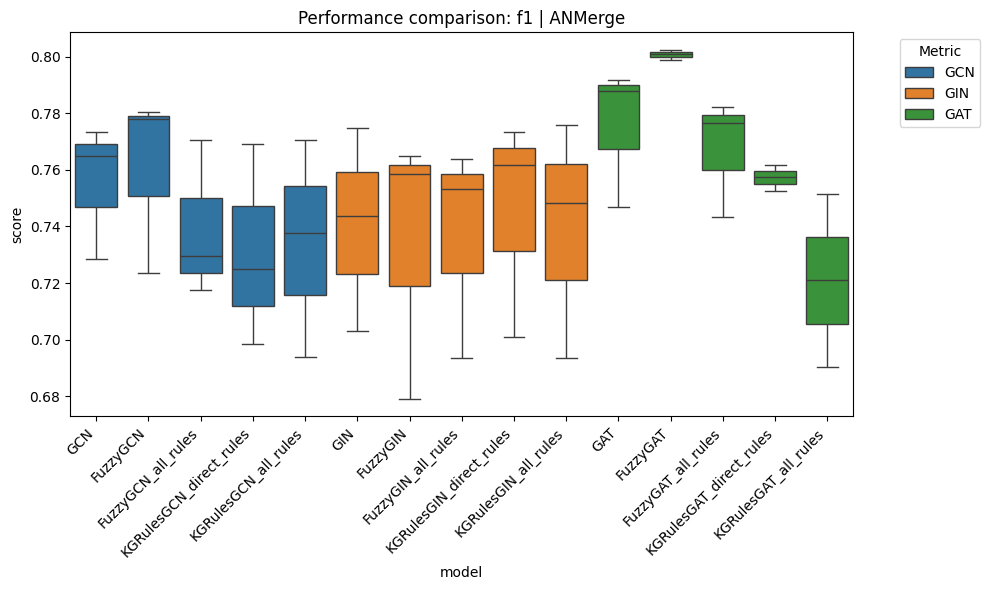

/tmp/ipykernel_506564/3652178690.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["backbone"] = plot_df["model"].apply(backbone)


<Figure size 1200x600 with 0 Axes>

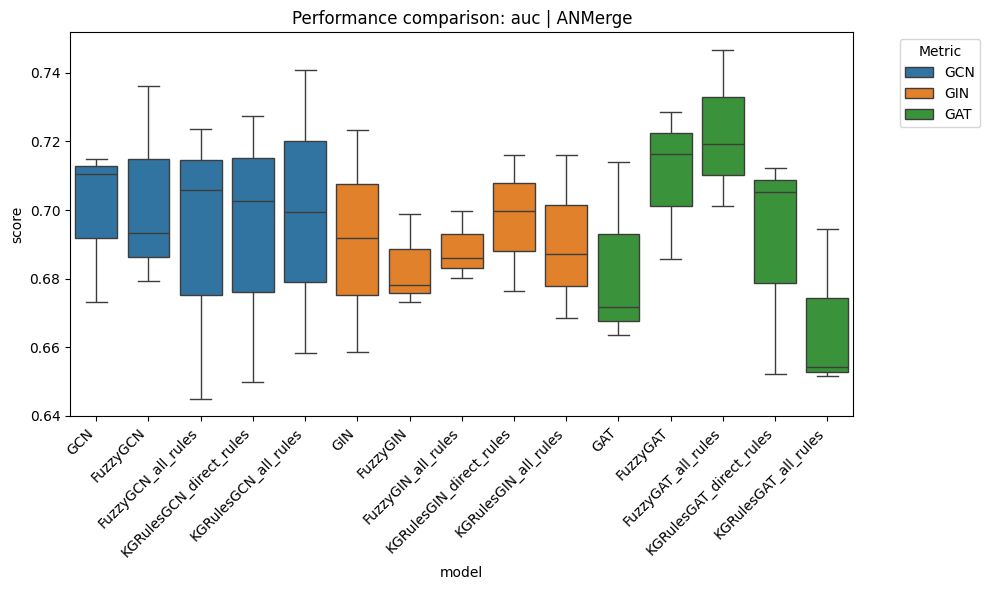

/tmp/ipykernel_506564/3652178690.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["backbone"] = plot_df["model"].apply(backbone)


<Figure size 1200x600 with 0 Axes>

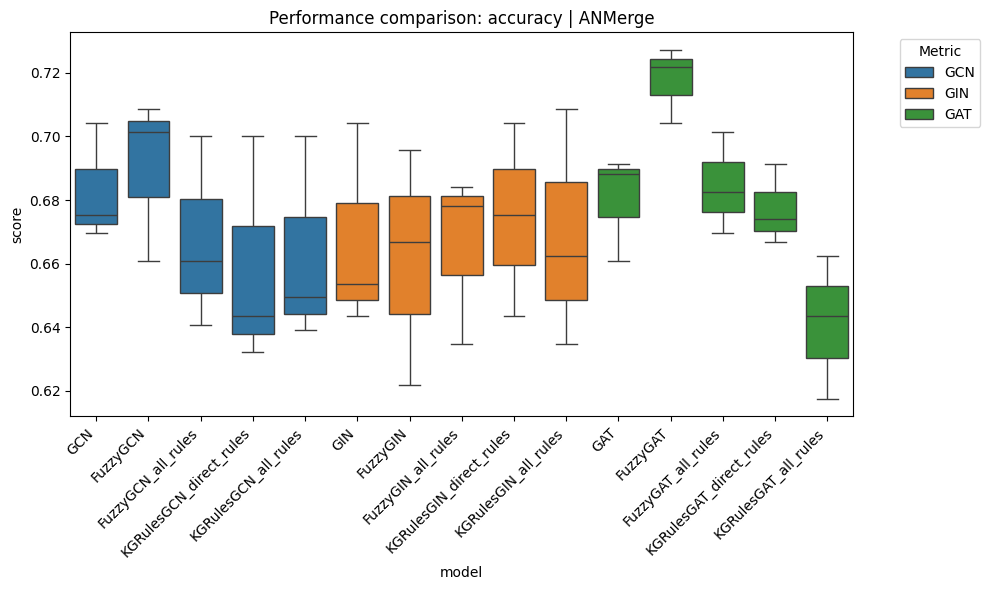

In [47]:
root_dir = "../nesy_gnn/results/AD_KG"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=["accuracy", "f1", "auc"],
    var_name="metric",
    value_name="score",
)
metric_name = 'f1'
dataset = 'ANMerge'
boxplot_comparison(df, 'f1', dataset)
boxplot_comparison(df, 'auc', dataset)
boxplot_comparison(df, 'accuracy', dataset)

### Models Performance with updated (more) metrics

In [9]:
root_dir = "../nesy_gnn/results/updated/AD_KG"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc'],
    var_name="metric",
    value_name="score",
)
df

,dataset,k,model,fold,metric,score
0,ANMerge,4,GAT,0,accuracy,0.696970
1,ANMerge,4,GAT,1,accuracy,0.665217
2,ANMerge,4,GAT,2,accuracy,0.656522
3,ANMerge,4,FuzzyGAT,0,accuracy,0.688312
4,ANMerge,4,FuzzyGAT,1,accuracy,0.643478
...,...,...,...,...,...,...
163,ANMerge,4,FuzzyGCN_direct_rules,1,auprc,0.809589
164,ANMerge,4,FuzzyGCN_direct_rules,2,auprc,0.807039
165,ANMerge,4,FuzzyGCN_all_rules,0,auprc,0.793035
166,ANMerge,4,FuzzyGCN_all_rules,1,auprc,0.823374


<Figure size 1200x600 with 0 Axes>

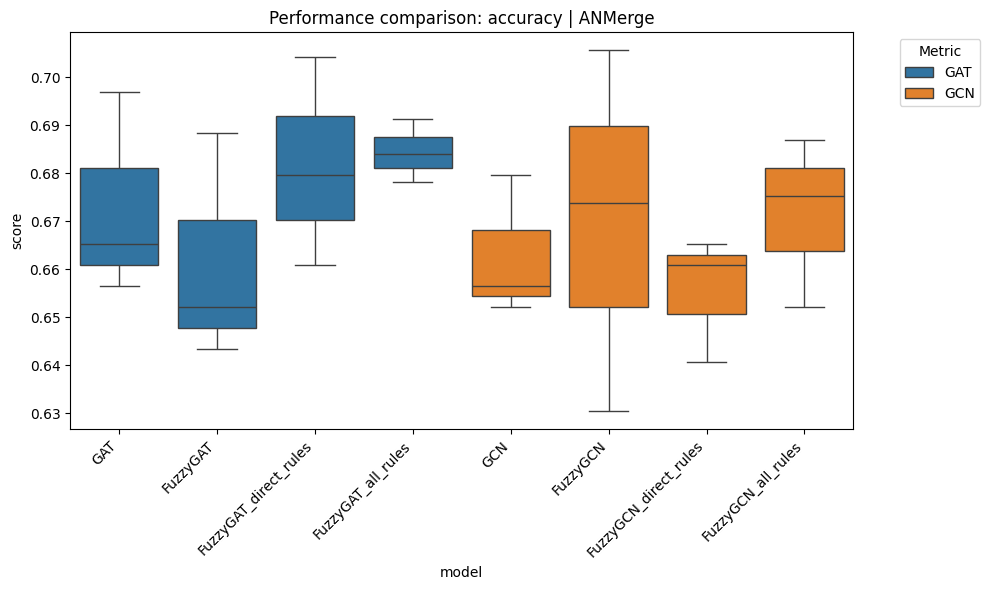

<Figure size 1200x600 with 0 Axes>

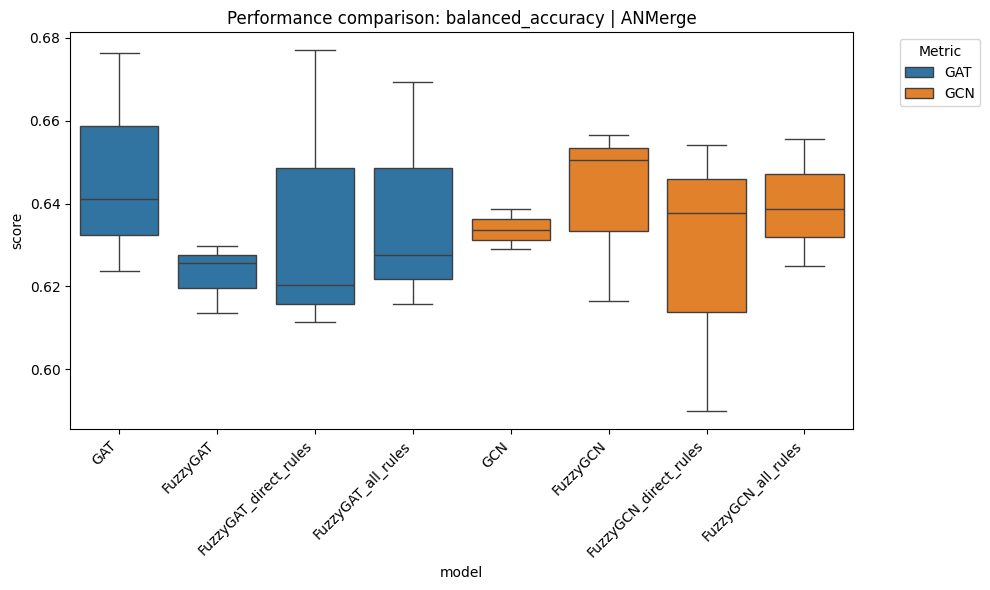

<Figure size 1200x600 with 0 Axes>

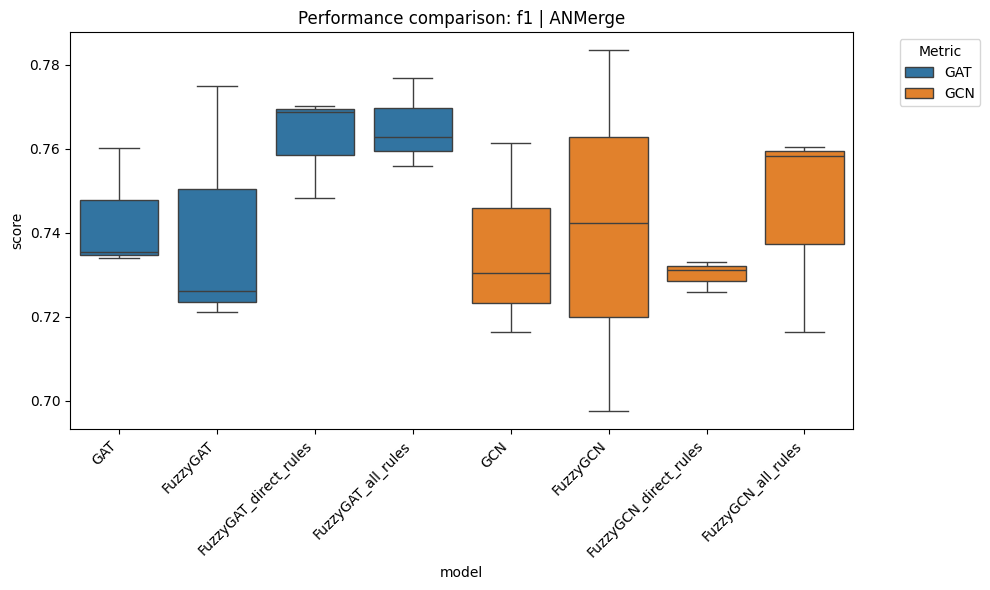

<Figure size 1200x600 with 0 Axes>

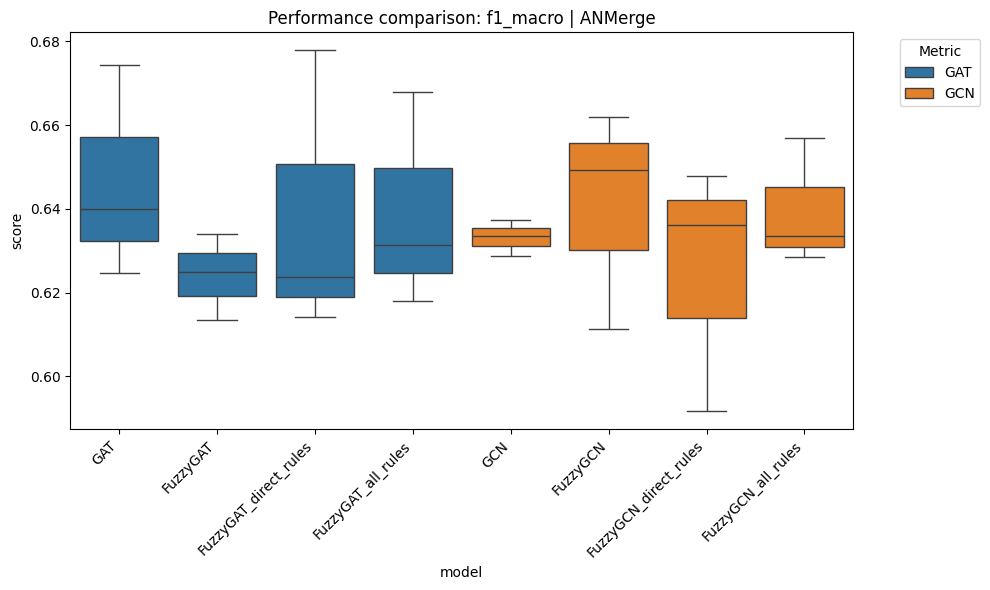

<Figure size 1200x600 with 0 Axes>

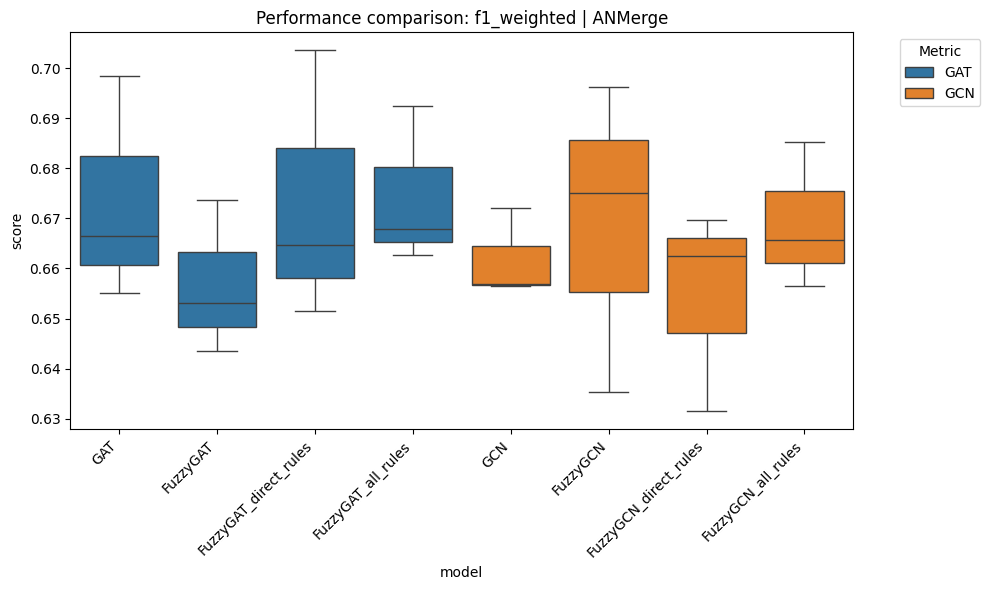

<Figure size 1200x600 with 0 Axes>

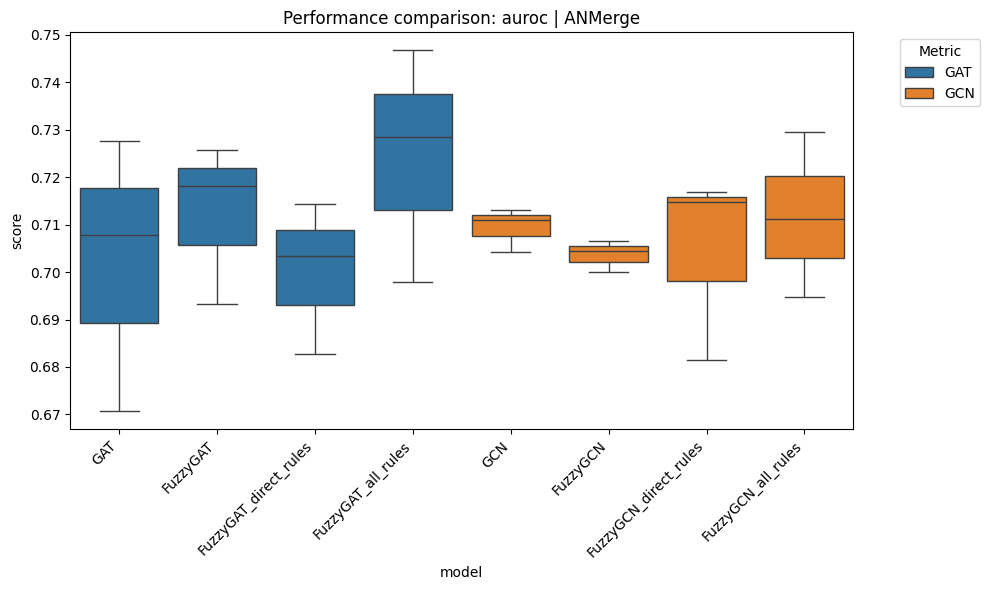

<Figure size 1200x600 with 0 Axes>

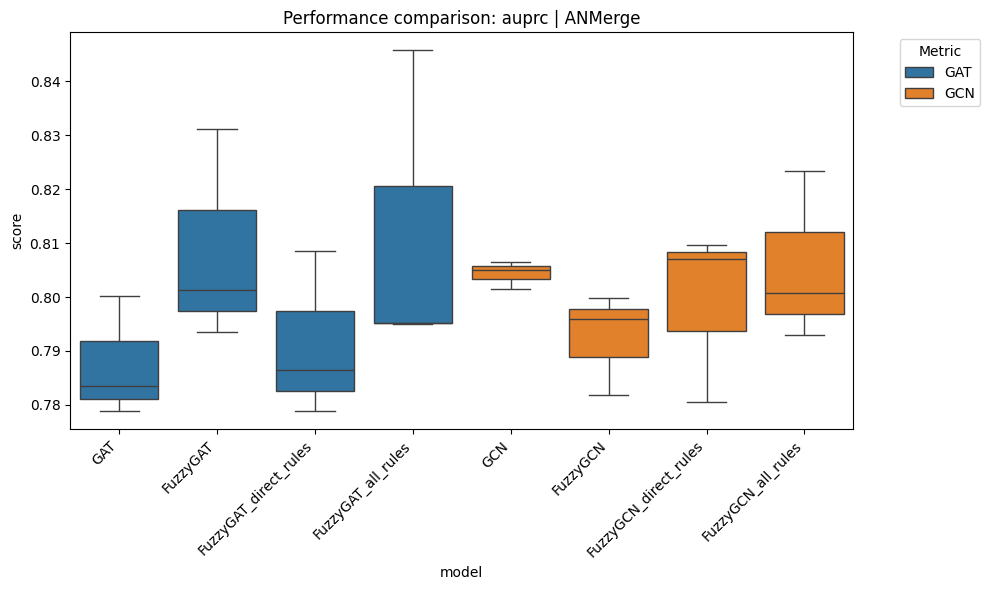

In [10]:
root_dir = "../nesy_gnn/results/updated/AD_KG"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc'],
    var_name="metric",
    value_name="score",
)
dataset = 'ANMerge'
for metric in ['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc']:
    boxplot_comparison(df, metric, dataset)


## Models with Explaining results

<Figure size 1200x600 with 0 Axes>

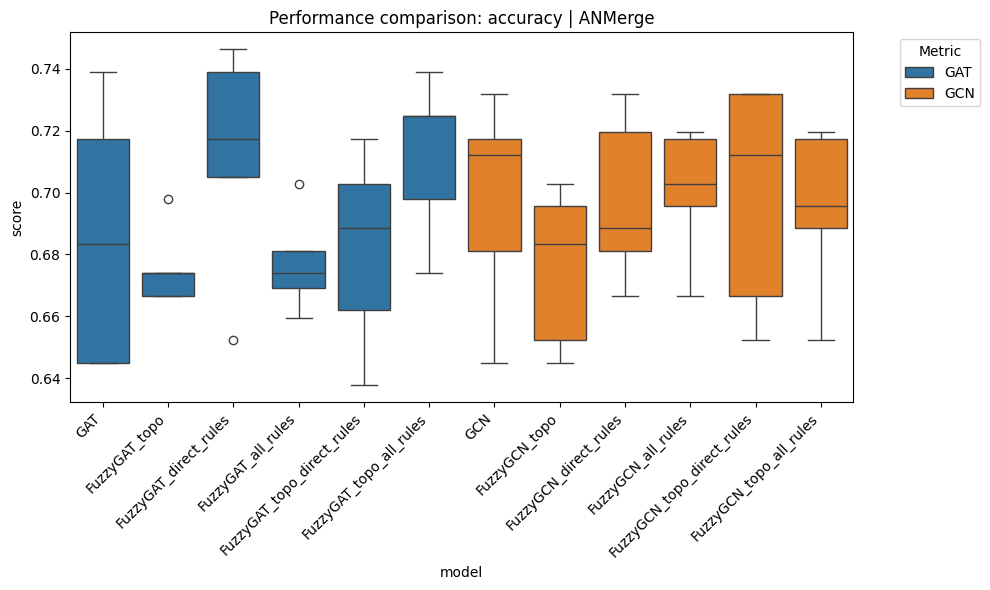

<Figure size 1200x600 with 0 Axes>

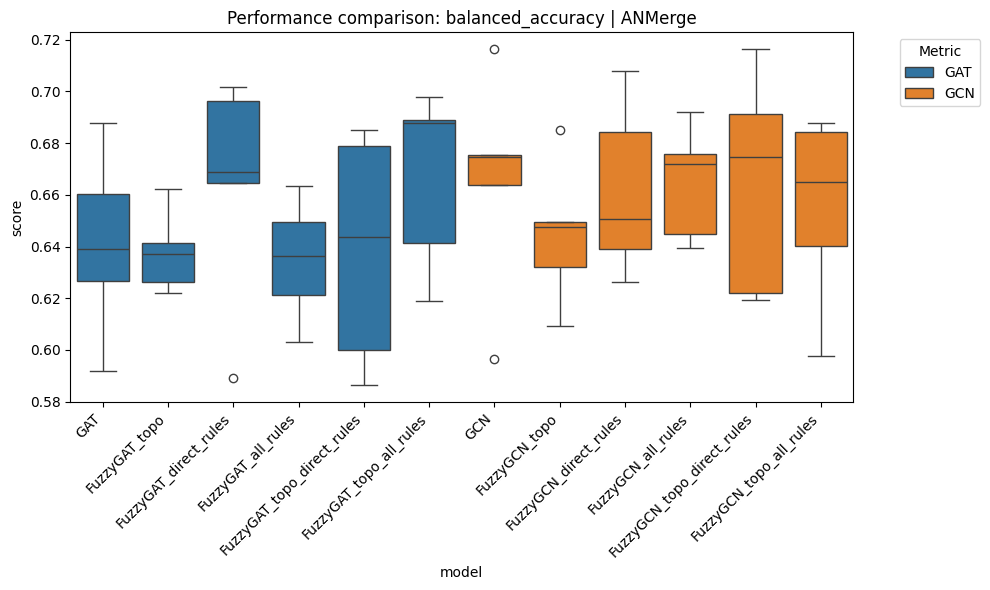

<Figure size 1200x600 with 0 Axes>

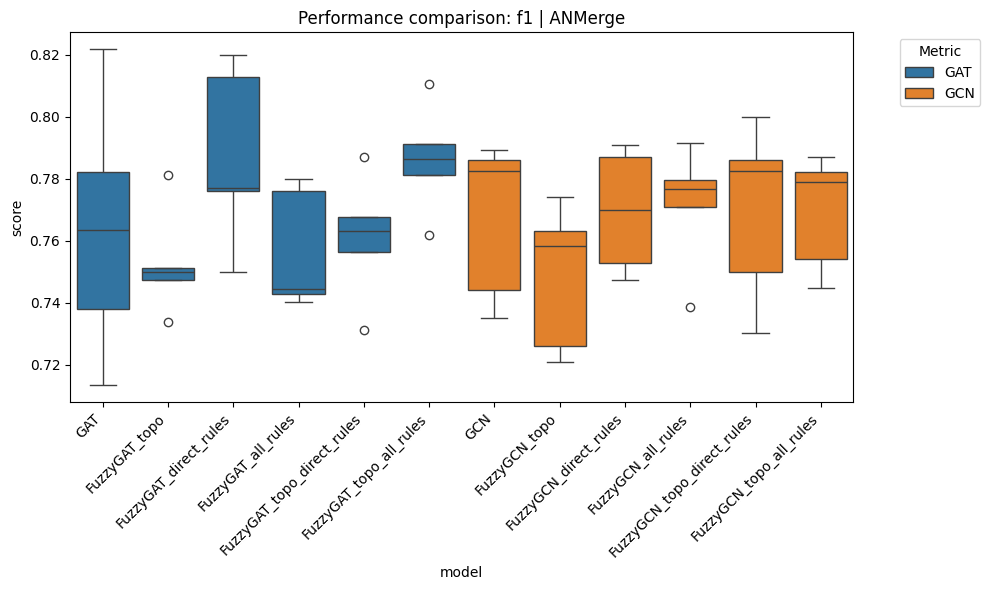

<Figure size 1200x600 with 0 Axes>

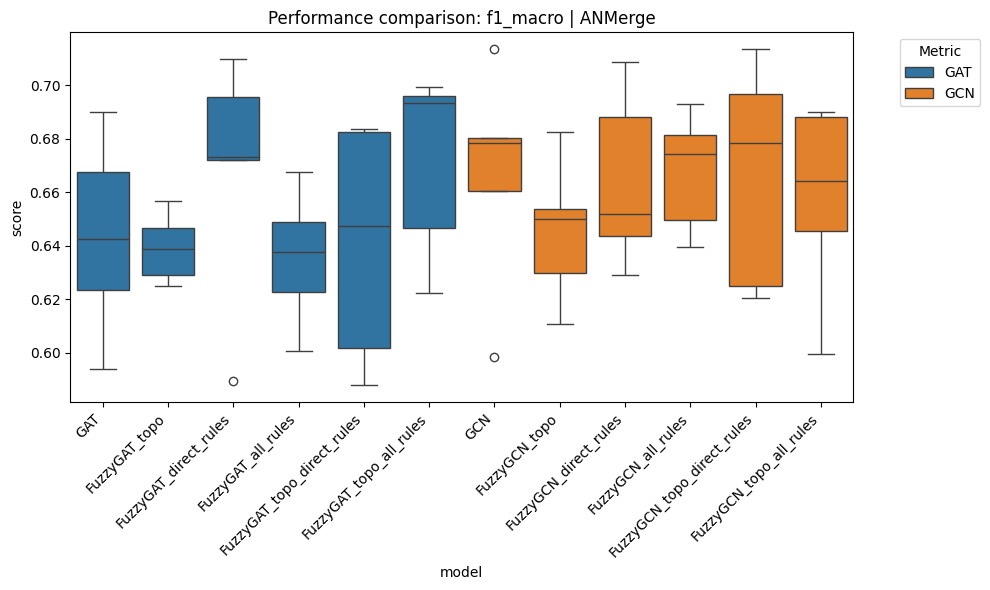

<Figure size 1200x600 with 0 Axes>

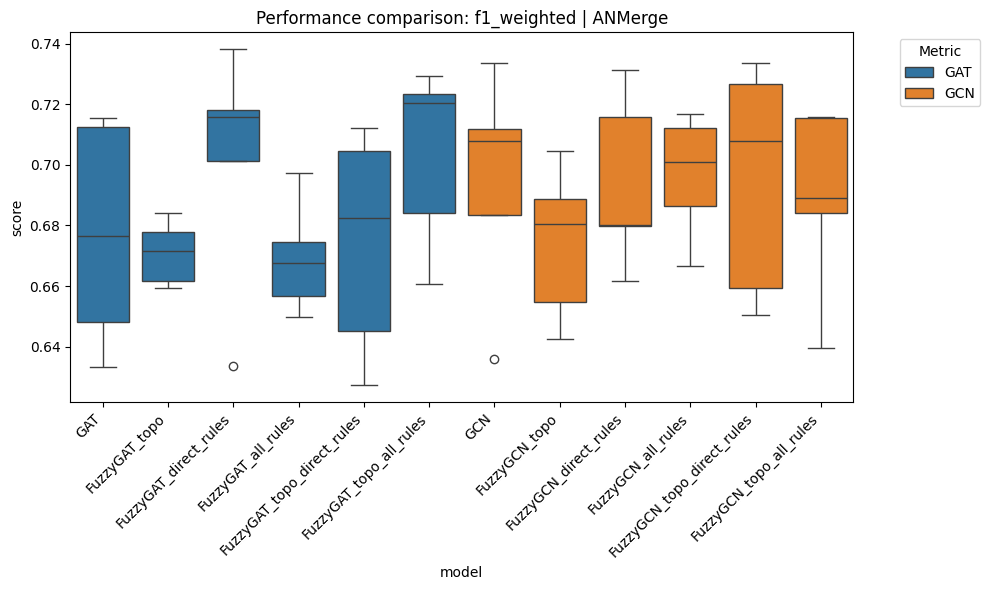

<Figure size 1200x600 with 0 Axes>

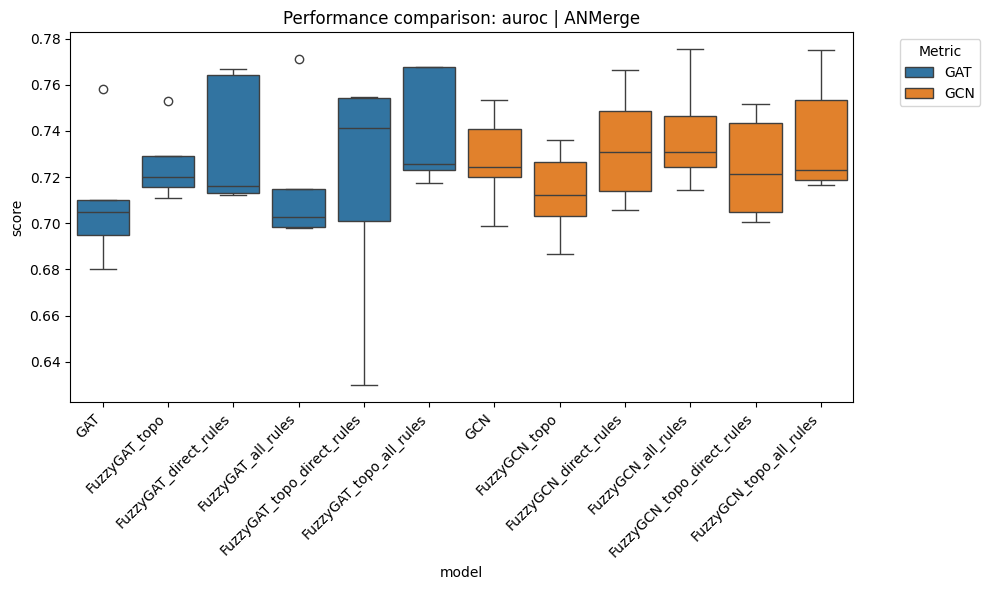

<Figure size 1200x600 with 0 Axes>

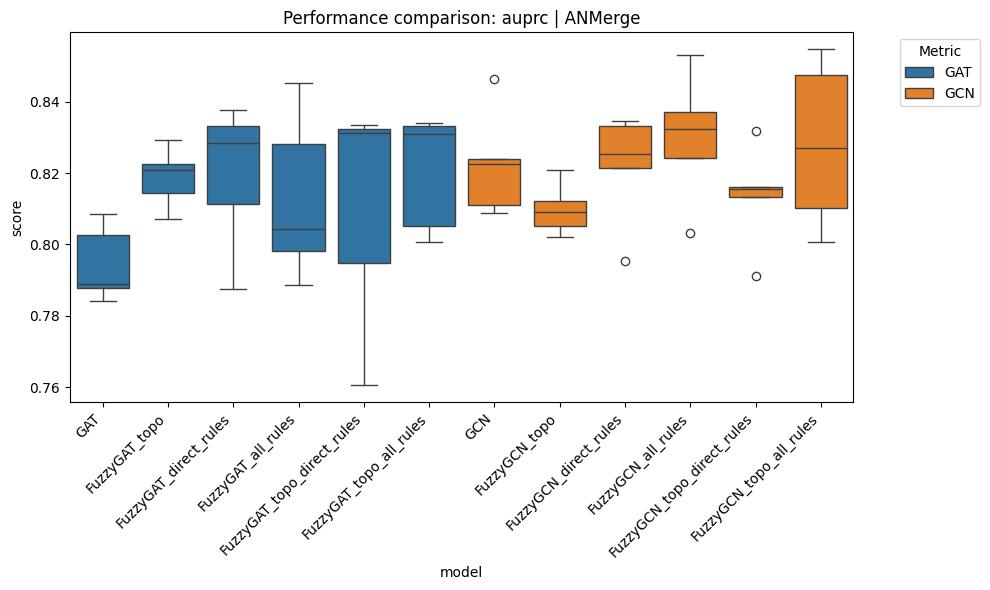

In [5]:
root_dir = "../nesy_gnn/results/explain/AD_KG"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc'],
    var_name="metric",
    value_name="score",
)
dataset = 'ANMerge'
for metric in ['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc']:
    boxplot_comparison(df, metric, dataset)

In [7]:
df_metrics

,model,fold,accuracy,balanced_accuracy,f1,f1_macro,f1_weighted,auroc,auprc,dataset,k
0,GAT,0,0.683453,0.638876,0.763441,0.642590,0.676498,0.694831,0.802573,ANMerge,4
1,GAT,1,0.739130,0.660170,0.821782,0.667648,0.712324,0.758312,0.808612,ANMerge,4
2,GAT,2,0.644928,0.592045,0.737968,0.593703,0.633428,0.680000,0.784016,ANMerge,4
3,GAT,3,0.717391,0.687727,0.782123,0.690031,0.715389,0.705000,0.787891,ANMerge,4
4,GAT,4,0.644928,0.626591,0.713450,0.623392,0.648191,0.710227,0.789039,ANMerge,4
5,FuzzyGAT_topo,0,0.697842,0.641348,0.781250,0.646439,0.684264,0.711011,0.820940,ANMerge,4
6,FuzzyGAT_topo,1,0.673913,0.637125,0.751381,0.638849,0.671467,0.753038,0.822664,ANMerge,4
7,FuzzyGAT_topo,2,0.666667,0.626364,0.747253,0.628946,0.661523,0.729318,0.829327,ANMerge,4
8,FuzzyGAT_topo,3,0.673913,0.662273,0.733728,0.656584,0.677826,0.715909,0.807033,ANMerge,4
9,FuzzyGAT_topo,4,0.666667,0.622045,0.750000,0.625000,0.659420,0.720000,0.814403,ANMerge,4


+ add dots and mean/std values on box

In [ ]:
def ceiling_div(n,d):
    return (n+d-1)//d

def backbone(model):
    if "GCN" in model:
        return "GCN"
    elif "GAT" in model:
        return "GAT"
    elif "GIN" in model:
        return "GIN"
    elif "RuleOnly" in model:
        return "RuleOnly"
    else:
        return "Other"

def variation_suffix(model):
    if "_" not in model:
        return "Baseline"
    else:
        suf = model.split("_")[1:]
        suffix = "_".join(suf)
        return suffix
    
# Four subplots (one for each base model type) in one figure
def boxplot_all_backbones_subplots(df, 
                                   metric_name: str, 
                                   dataset: str, 
                                   k: str|int=4,
                                   output_dir=None):
    # Filter and copy to avoid SettingWithCopyWarning
    plot_df = df[
        (df["metric"] == metric_name) & 
        (df["k"] == str(k)) &
        (df['dataset']==dataset)
    ].copy()
    
    plot_df["backbone"] = plot_df["model"].apply(backbone)
    
    backbones = sorted(plot_df['backbone'].unique())
    num_subplots = len(backbones)
    
    # Create grid based on number of backbones
    fig, axes = plt.subplots(2, ceiling_div(num_subplots, 2), figsize=(16, 12))
    axes = axes.flatten()
    subplot_colors = sns.color_palette("pastel", n_colors=num_subplots)
    
    for i, bb in enumerate(backbones):
        ax = axes[i]
        bb_df = plot_df[plot_df["backbone"] == bb]
        
        # Explicit order to ensure boxplot, dots, and text all align
        model_order = bb_df['model'].unique()
        
        # 1. Plot the boxes
        sns.boxplot(
            data=bb_df,
            x="model",
            y="score",
            hue="model",
            ax=ax,
            palette="Set2",
            legend=False,
            order=model_order
        )
        
        # 2. Add data dots
        sns.stripplot(
            data=bb_df,
            x="model",
            y="score",
            color="black",
            alpha=0.5,
            jitter=True,
            size=5,
            ax=ax,
            order=model_order
        )
        
        # 3. Calculate and annotate Mean & Std inside boxes
        for idx, m in enumerate(model_order):
            scores = bb_df[bb_df["model"] == m]["score"]
            mean_val = scores.mean()
            std_val = scores.std()
            
            # Place text at the mean coordinate
            ax.text(
                idx, mean_val, 
                f"{mean_val:.3f}\n±{std_val:.3f}", 
                ha='center', va='center', 
                color='black', fontsize=9, fontweight='bold',
                bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', boxstyle='round,pad=0.2')
            )
        
        ax.set_title(f"{bb} Variations", fontsize=16)
        ax.set_xlabel("")
        ax.set_ylabel(metric_name.capitalize(), fontsize=10)
        ax.tick_params(axis='x', rotation=45)
        
    # Remove any empty subplots (if num_subplots is odd)
    for j in range(num_subplots, len(axes)):
        fig.delaxes(axes[j])
        
    fig.suptitle(f"Performance comparison: {metric_name.capitalize()} | {dataset} | k={k}", fontsize=20)
    plt.tight_layout()
    
    # --- SAVE PLOT LOGIC ---
    if output_dir:
        os.makedirs(output_dir, exist_ok=True) 
        filename = f"all_backbones_{dataset}_k{k}_{metric_name}.png"
        filepath = os.path.join(output_dir, filename)
        plt.savefig(filepath, dpi=300, bbox_inches='tight') # dpi=300 for high quality
        print(f"Saved plot to: {filepath}")
        
    plt.show()


# 2. Plot variations for only ONE specified backbone
def boxplot_single_backbone(df, 
                            metric_name: str, 
                            dataset: str, 
                            target_backbone: str, 
                            k: str|int=4,
                            output_dir=None):
    plot_df = df[
        (df["metric"] == metric_name) & 
        (df["k"] == str(k)) &
        (df['dataset']==dataset)
    ].copy()
    
    plot_df["backbone"] = plot_df["model"].apply(backbone)
    plot_df = plot_df[plot_df["backbone"] == target_backbone]

    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Explicit order
    model_order = plot_df['model'].unique()

    # 1. Plot the boxes
    sns.boxplot(
        data=plot_df,
        x="model",
        y="score",
        hue="model",
        ax=ax,
        palette="Set2",
        legend=False,
        order=model_order
    )
    
    # 2. Add data dots
    sns.stripplot(
        data=plot_df,
        x="model",
        y="score",
        color="black",
        alpha=0.5,
        jitter=True,
        size=5,
        ax=ax,
        order=model_order
    )
    
    # 3. Calculate and annotate Mean & Std inside boxes
    for idx, m in enumerate(model_order):
        scores = plot_df[plot_df["model"] == m]["score"]
        mean_val = scores.mean()
        std_val = scores.std()
        
        # Place text at the mean coordinate
        ax.text(
            idx, mean_val, 
            f"{mean_val:.3f}\n±{std_val:.3f}", 
            ha='center', va='center', 
            color='black', fontsize=10, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', boxstyle='round,pad=0.2')
        )

    plt.xticks(rotation=45, ha="right")
    plt.title(f"{target_backbone} Variations: {metric_name.capitalize()} | {dataset} | k={k}")
    plt.ylabel(metric_name.capitalize())
    plt.xlabel("Model")
    plt.tight_layout()

    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        filename = f"{target_backbone}_{dataset}_k{k}_{metric_name}.png"
        filepath = os.path.join(output_dir, filename)
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
        print(f"Saved plot to: {filepath}")
    #plt.show()

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_accuracy.png


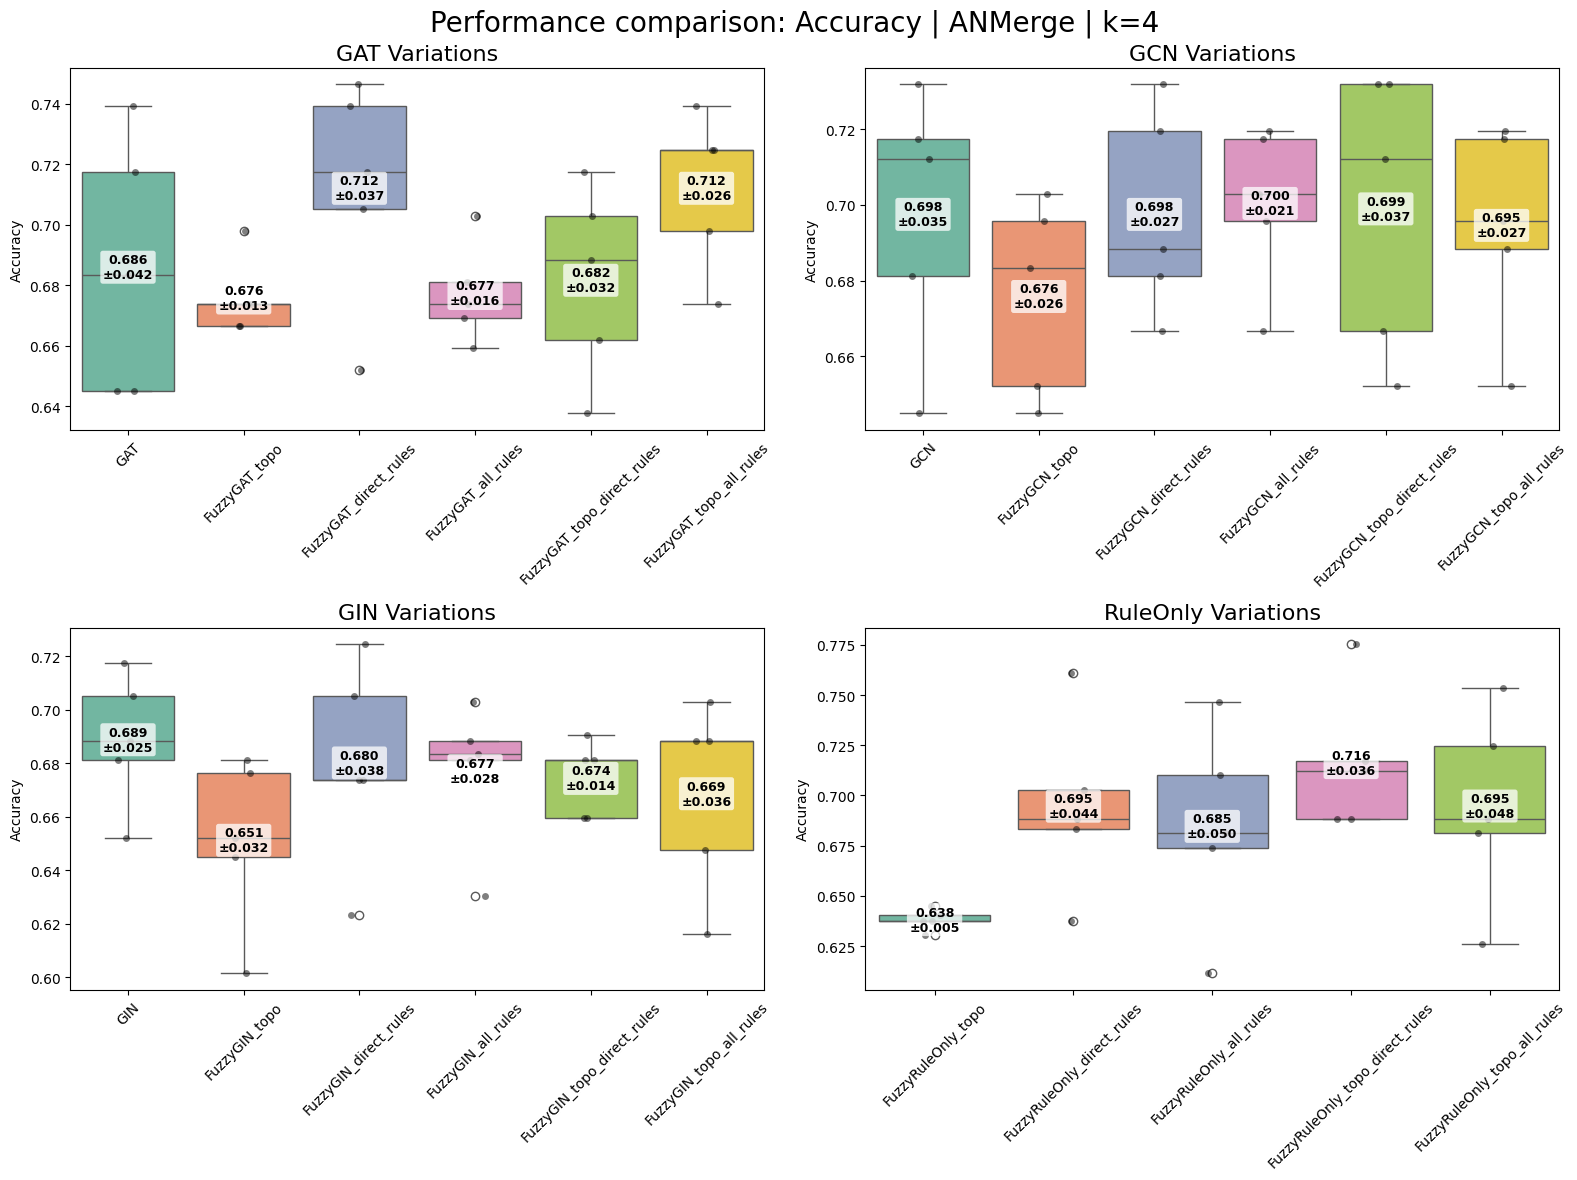

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GAT_ANMerge_k4_accuracy.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GCN_ANMerge_k4_accuracy.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GIN_ANMerge_k4_accuracy.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/RuleOnly_ANMerge_k4_accuracy.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_balanced_accuracy.png


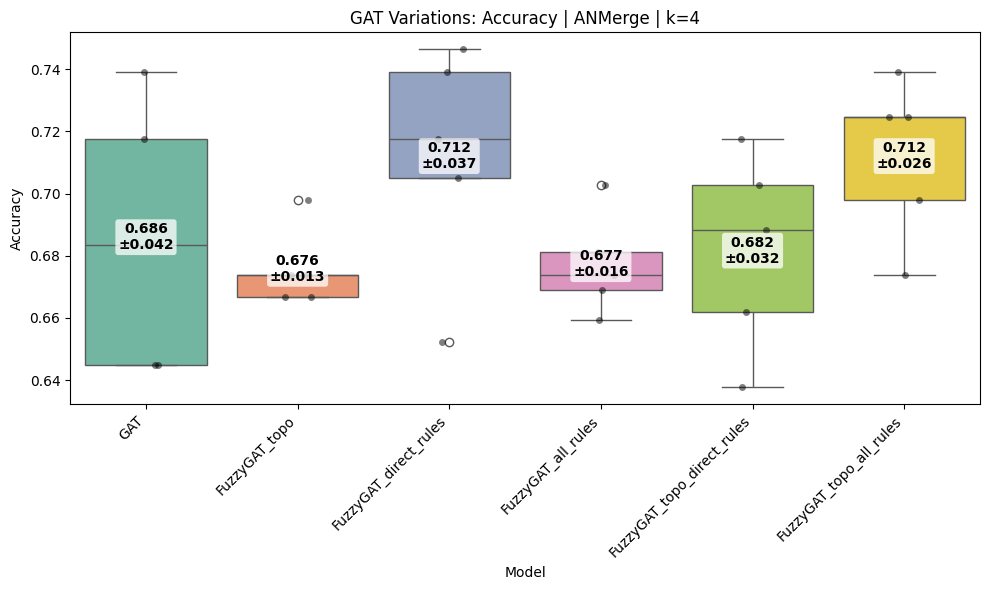

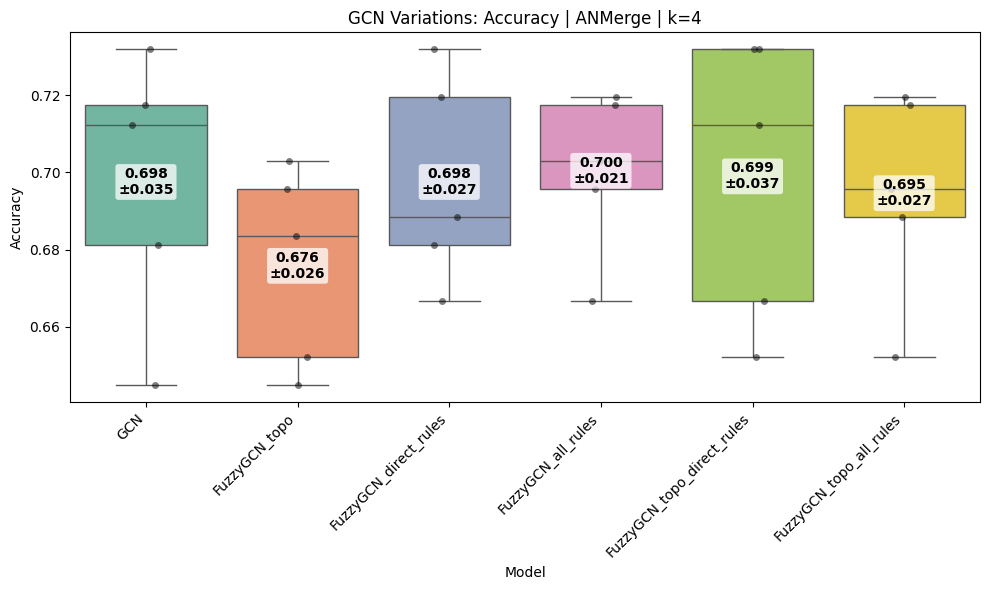

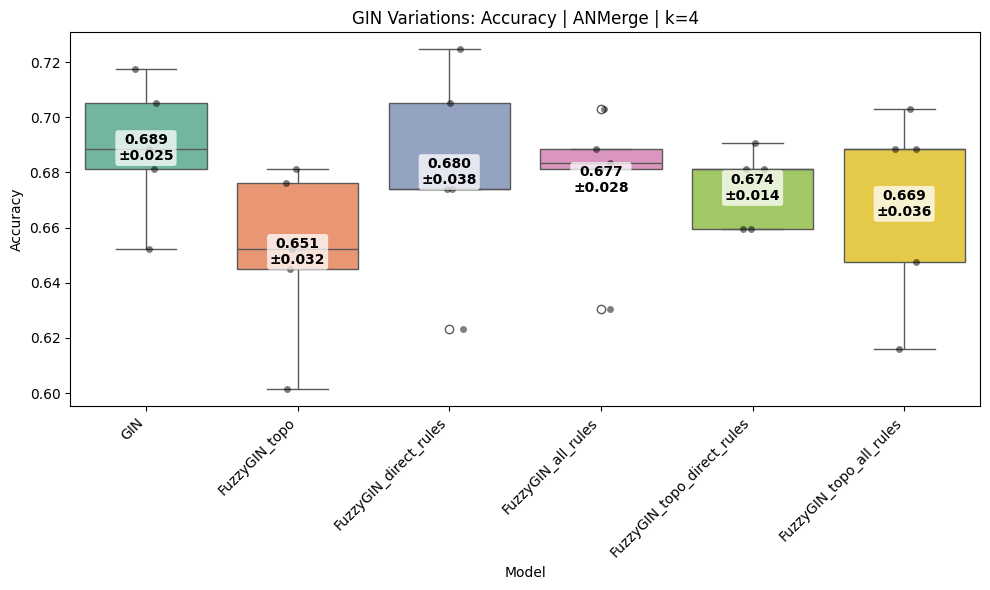

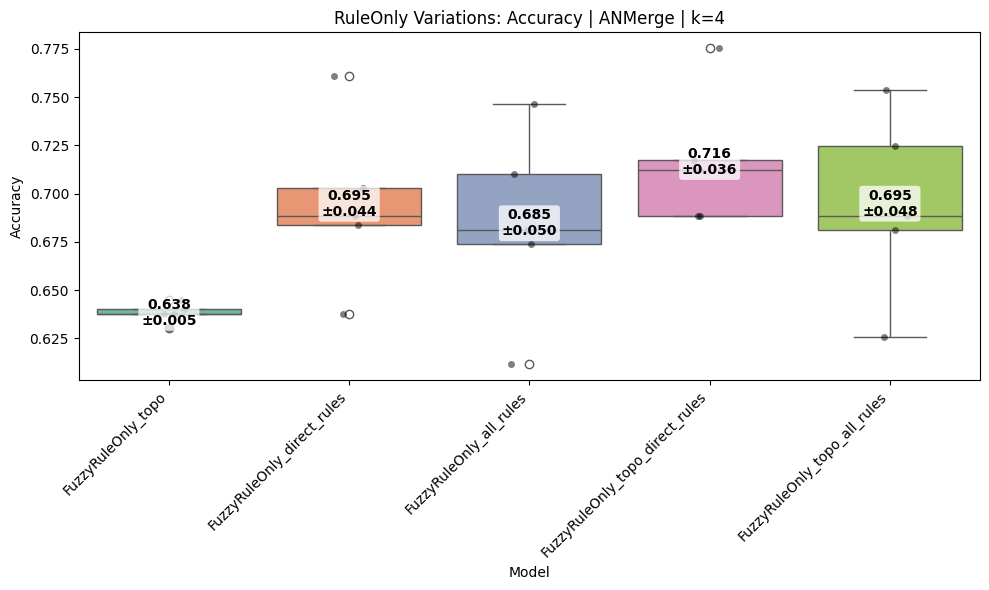

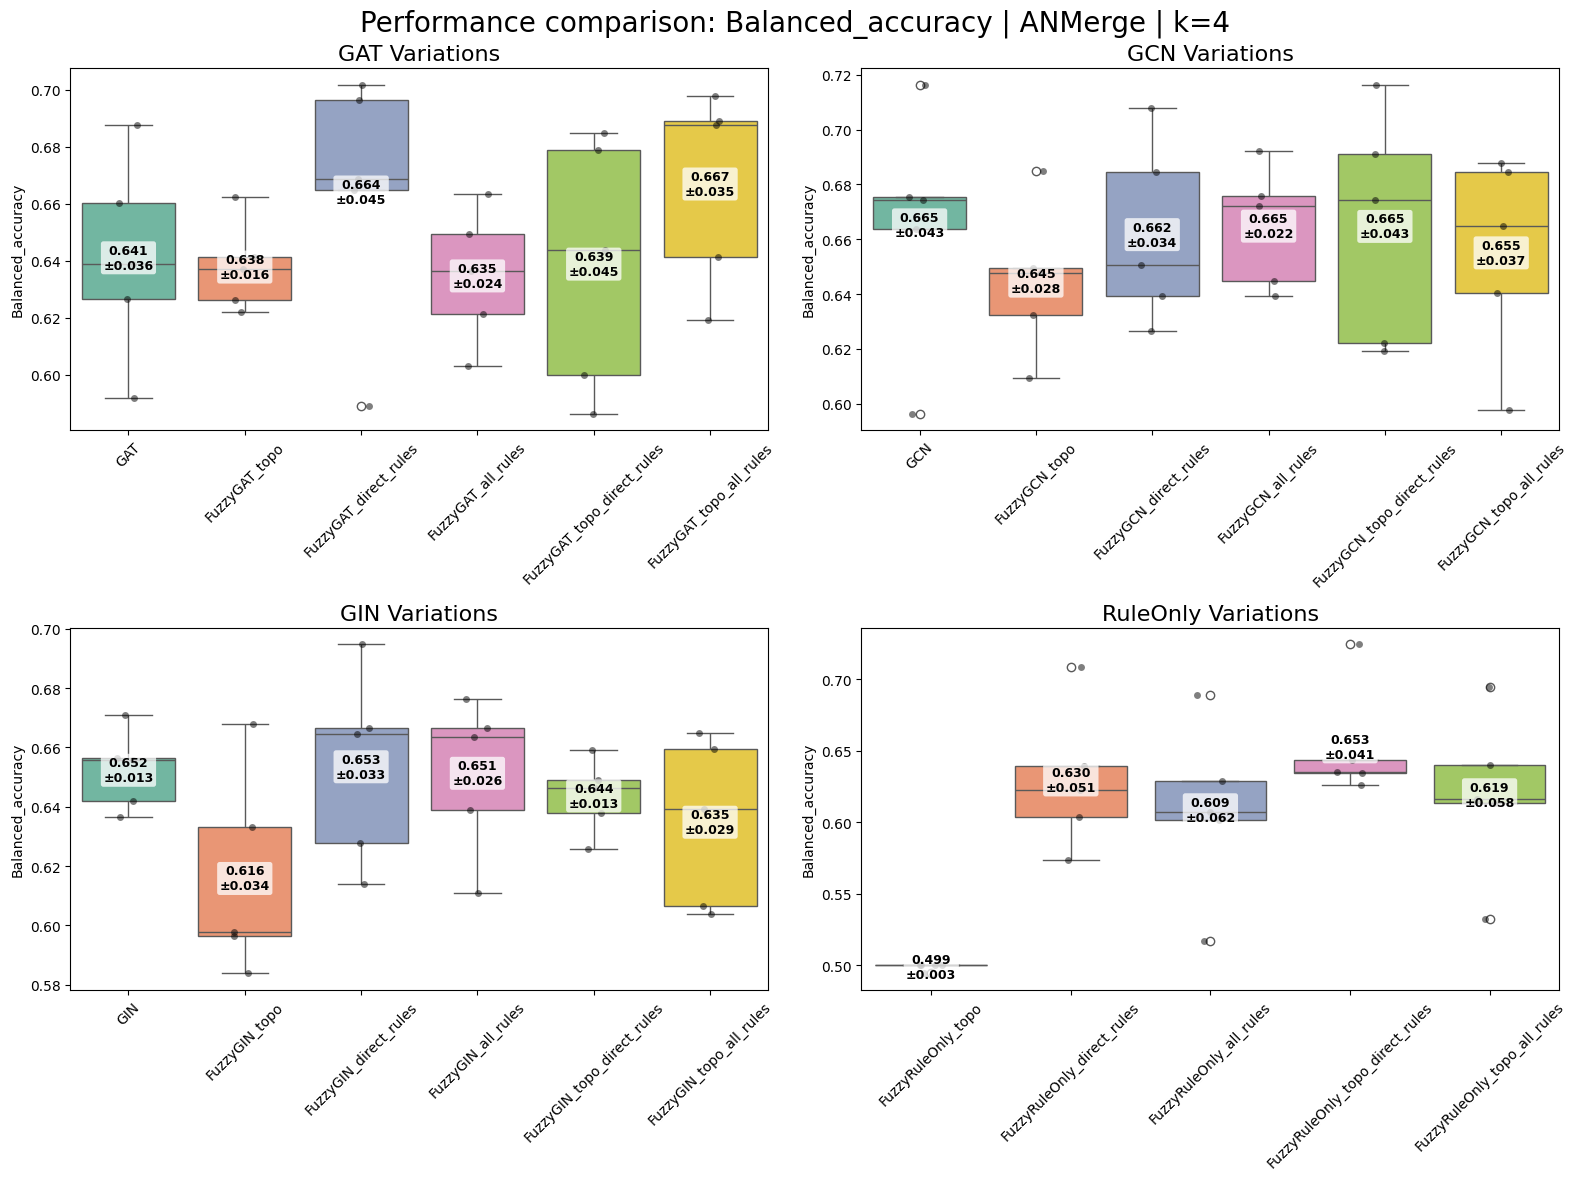

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GAT_ANMerge_k4_balanced_accuracy.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GCN_ANMerge_k4_balanced_accuracy.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GIN_ANMerge_k4_balanced_accuracy.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/RuleOnly_ANMerge_k4_balanced_accuracy.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_f1.png


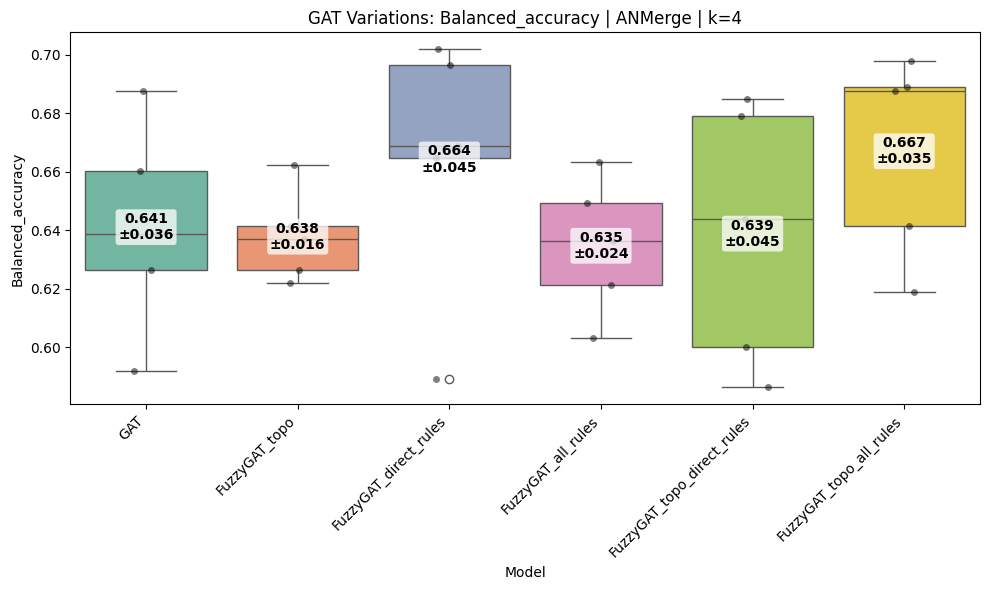

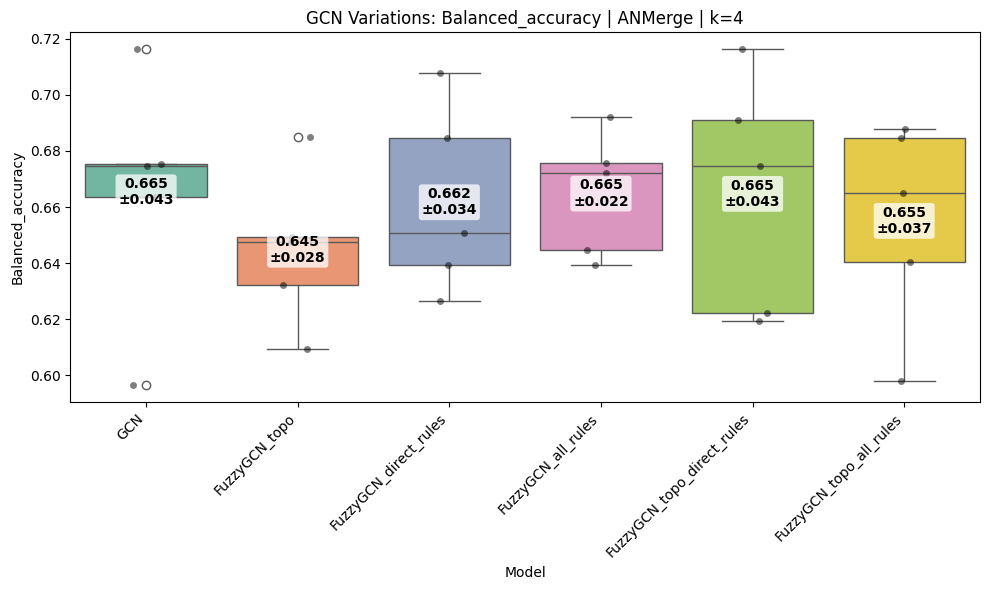

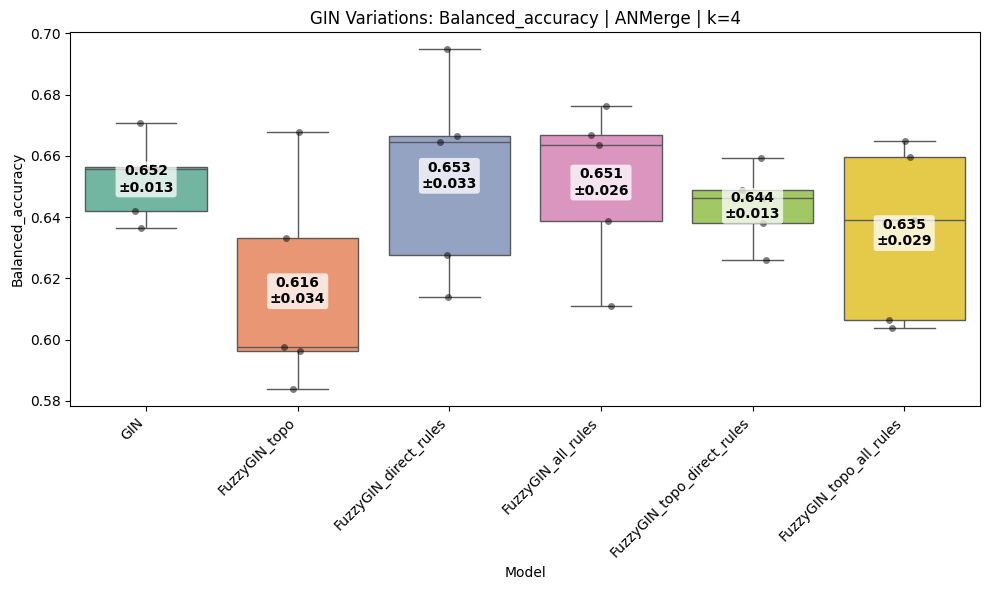

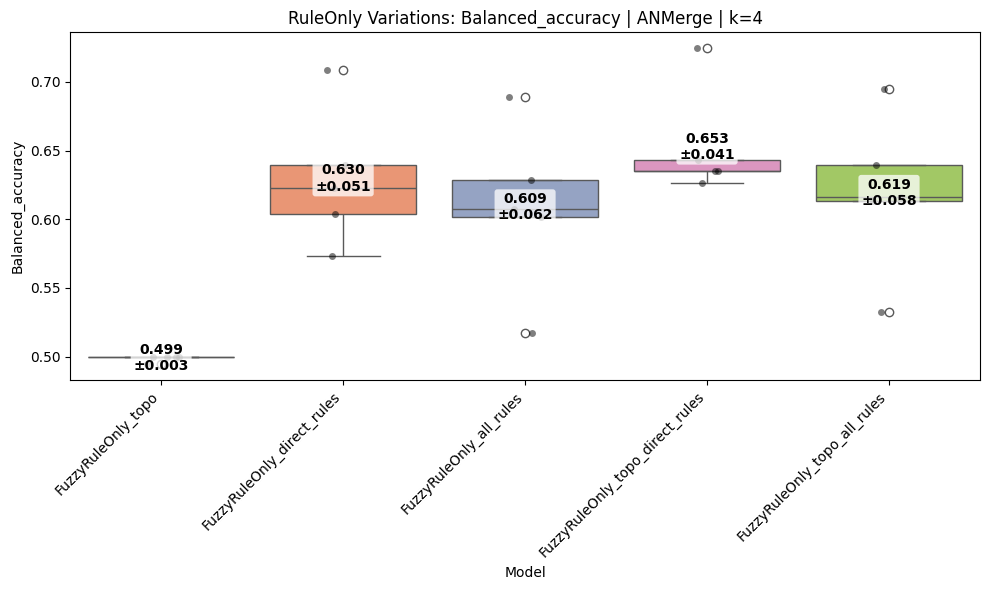

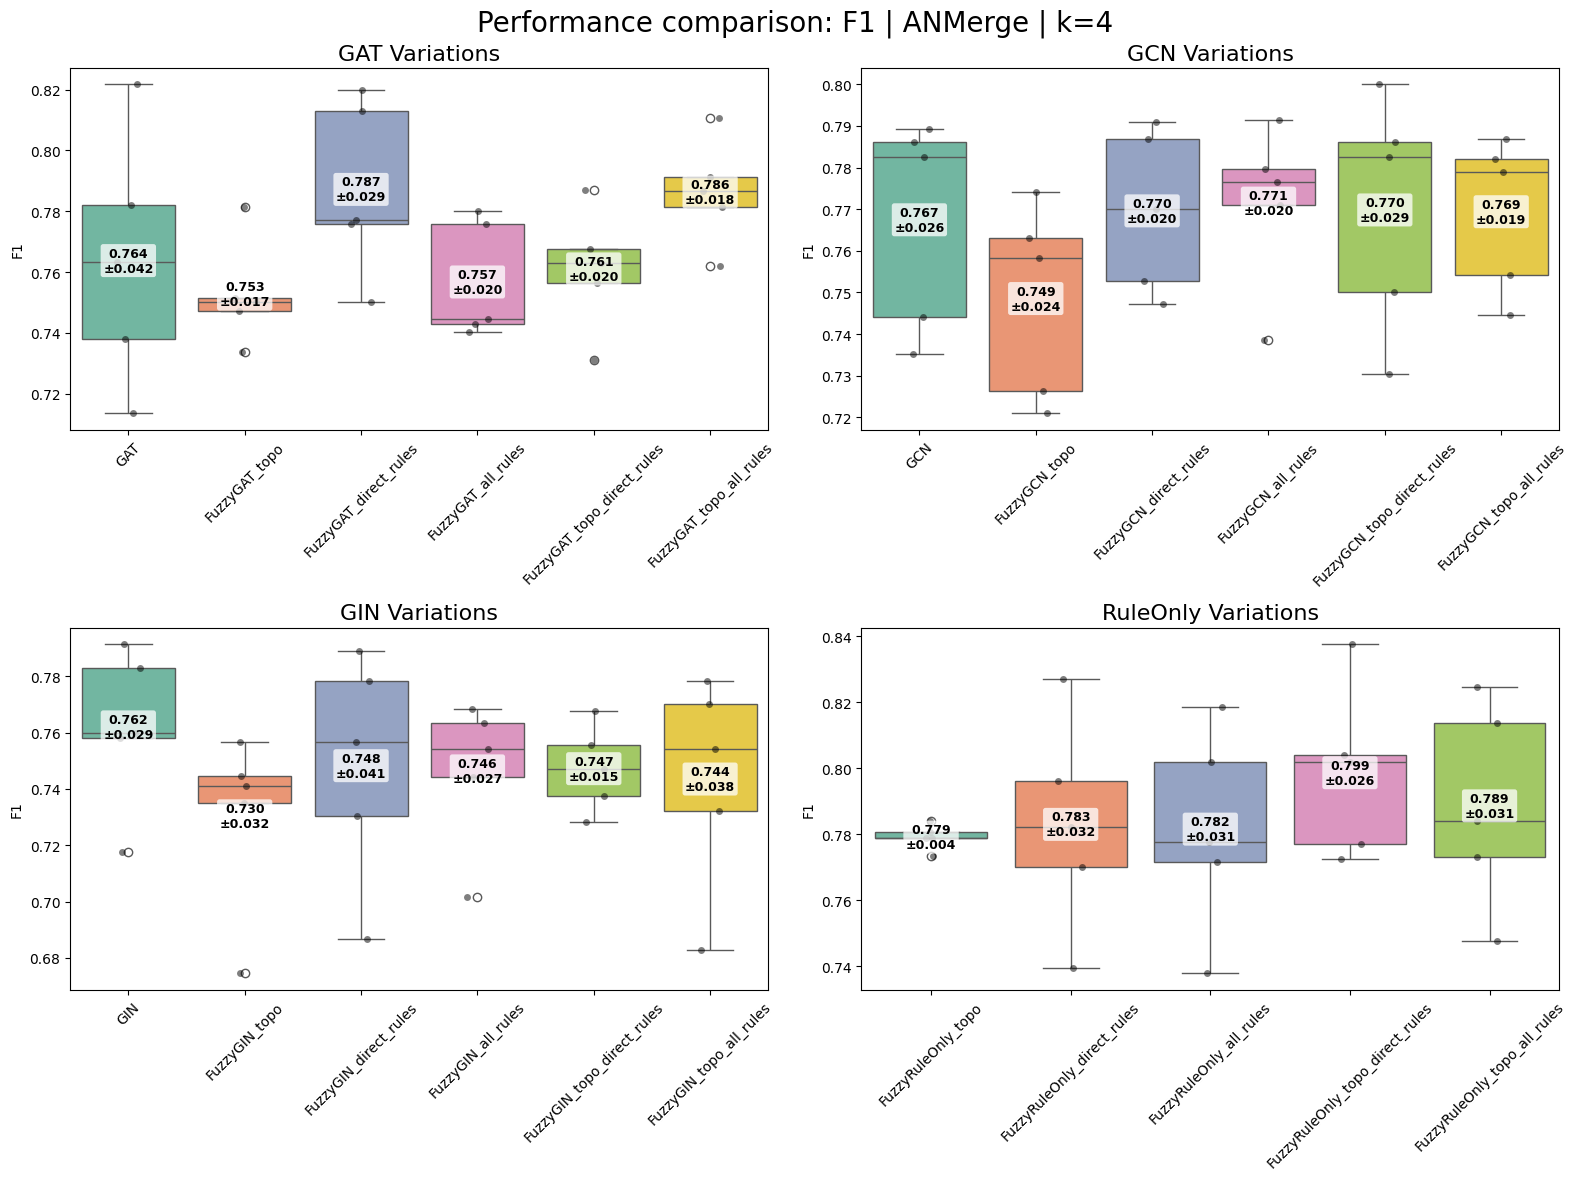

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GAT_ANMerge_k4_f1.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GCN_ANMerge_k4_f1.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GIN_ANMerge_k4_f1.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/RuleOnly_ANMerge_k4_f1.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_f1_macro.png


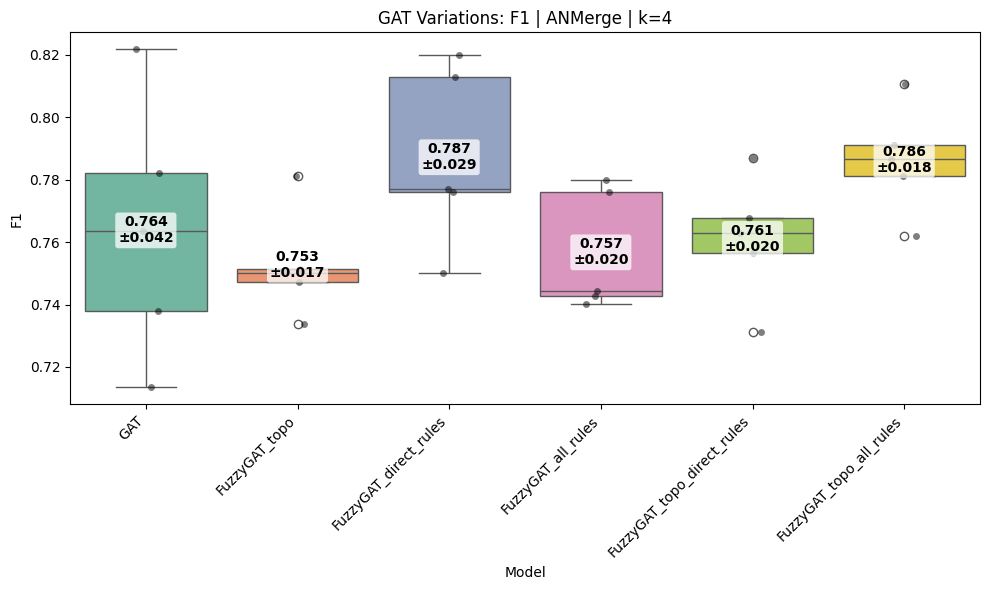

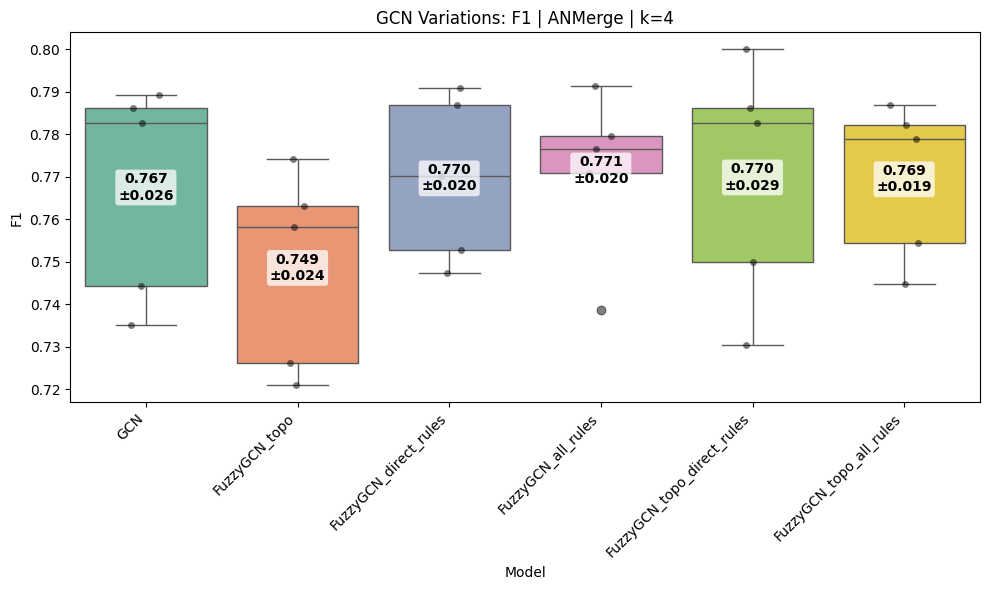

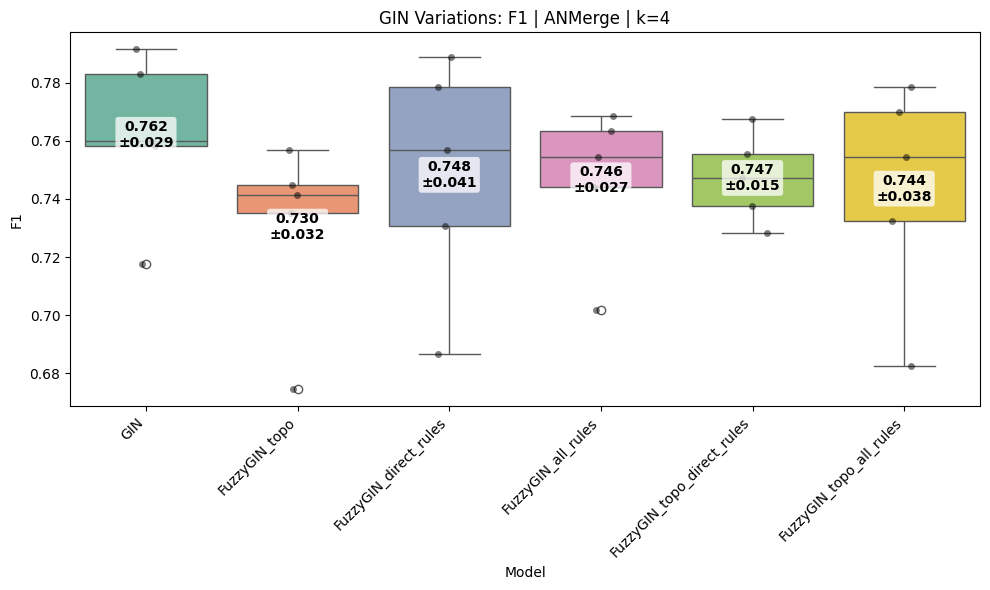

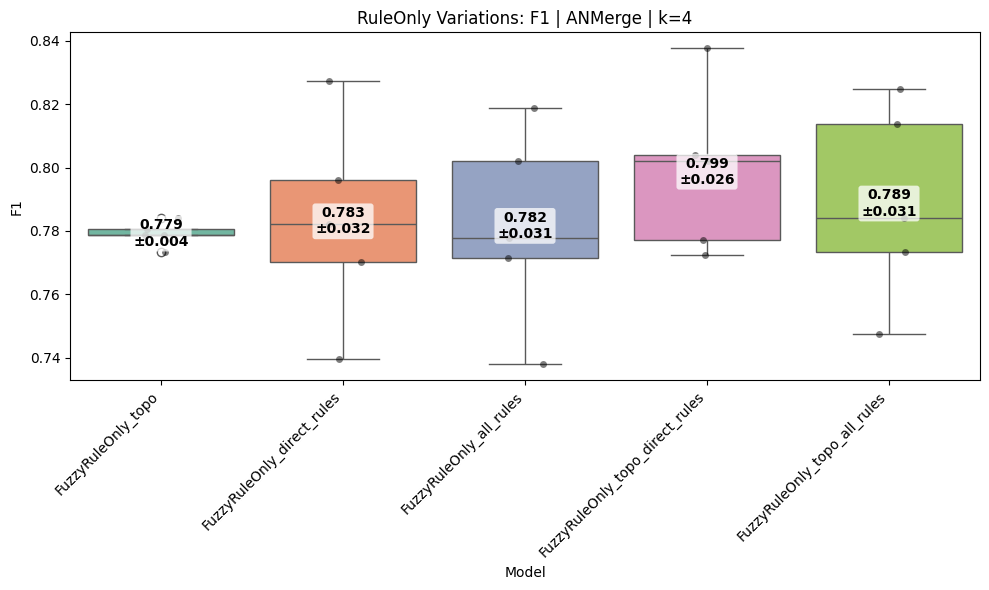

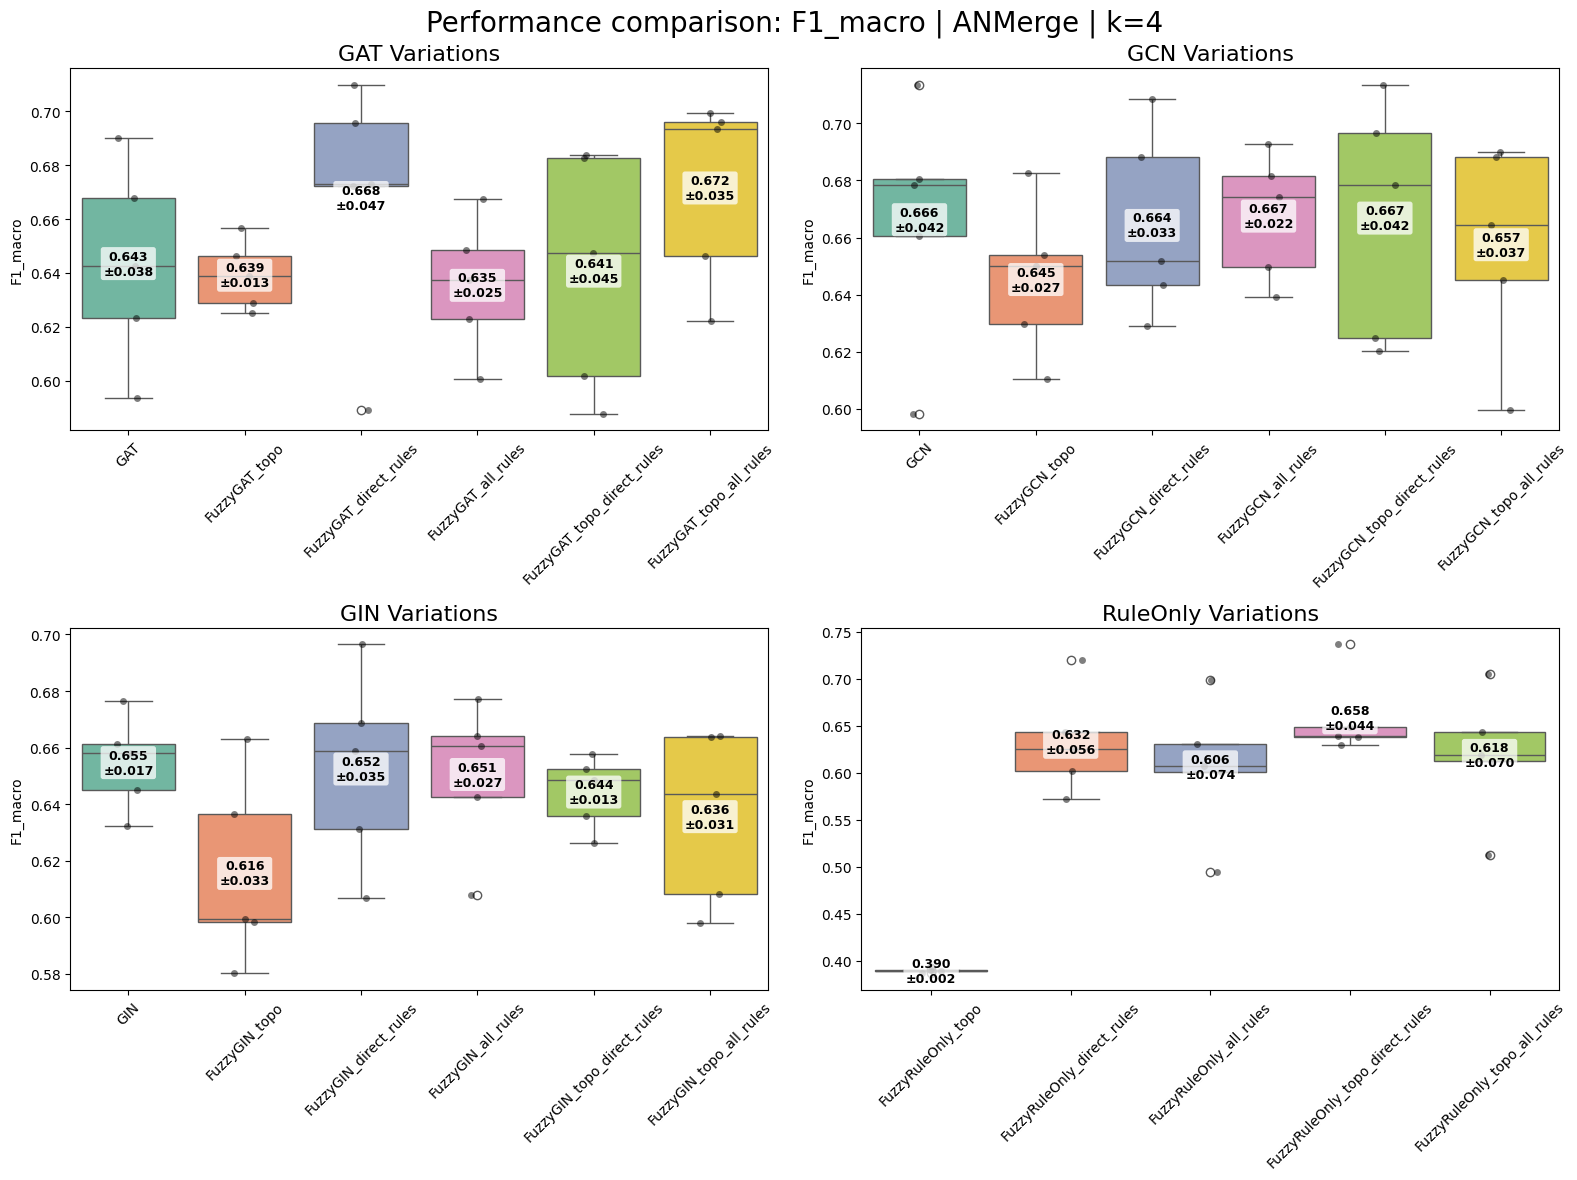

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GAT_ANMerge_k4_f1_macro.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GCN_ANMerge_k4_f1_macro.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GIN_ANMerge_k4_f1_macro.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/RuleOnly_ANMerge_k4_f1_macro.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_f1_weighted.png


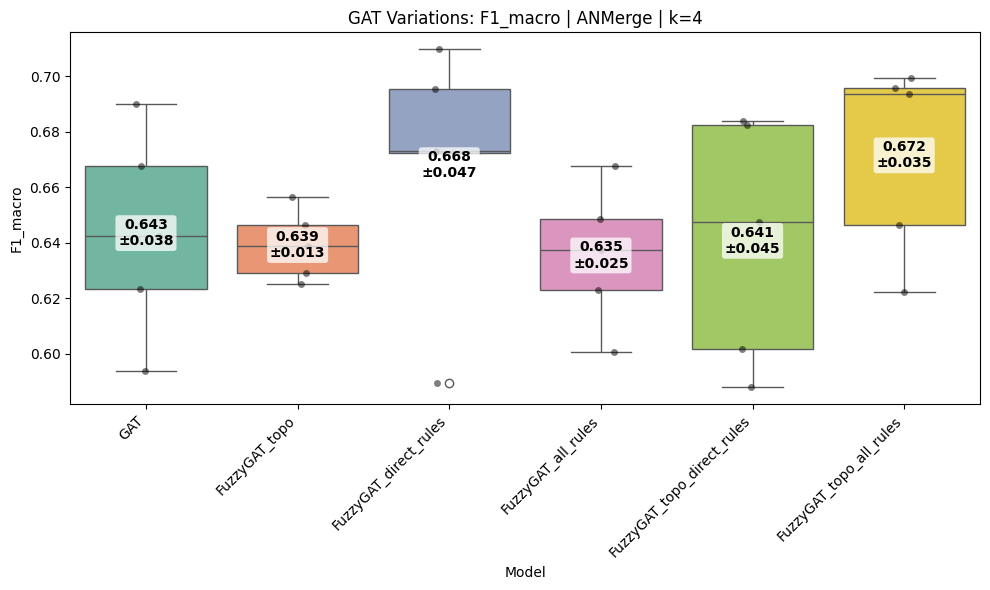

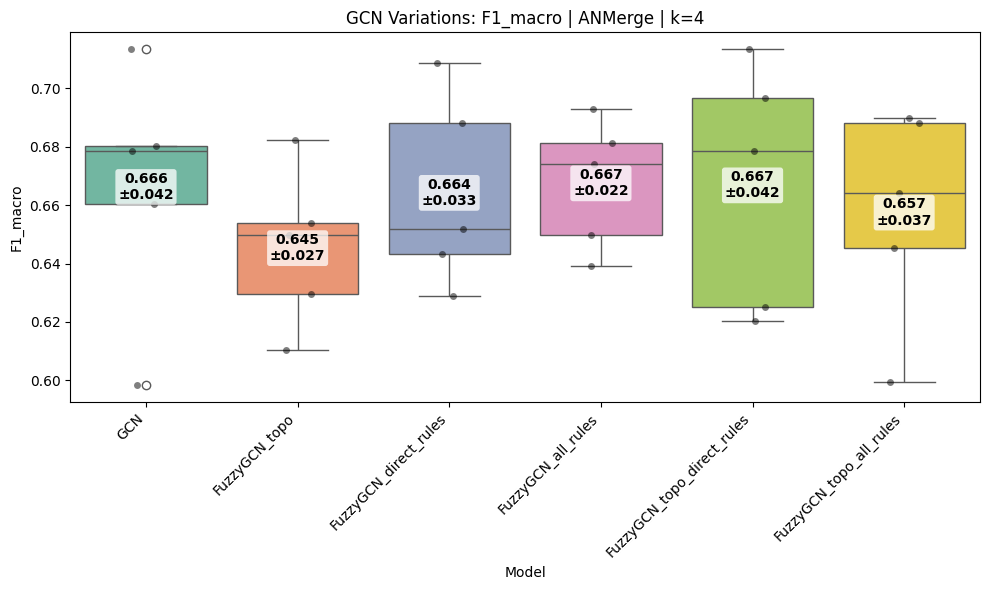

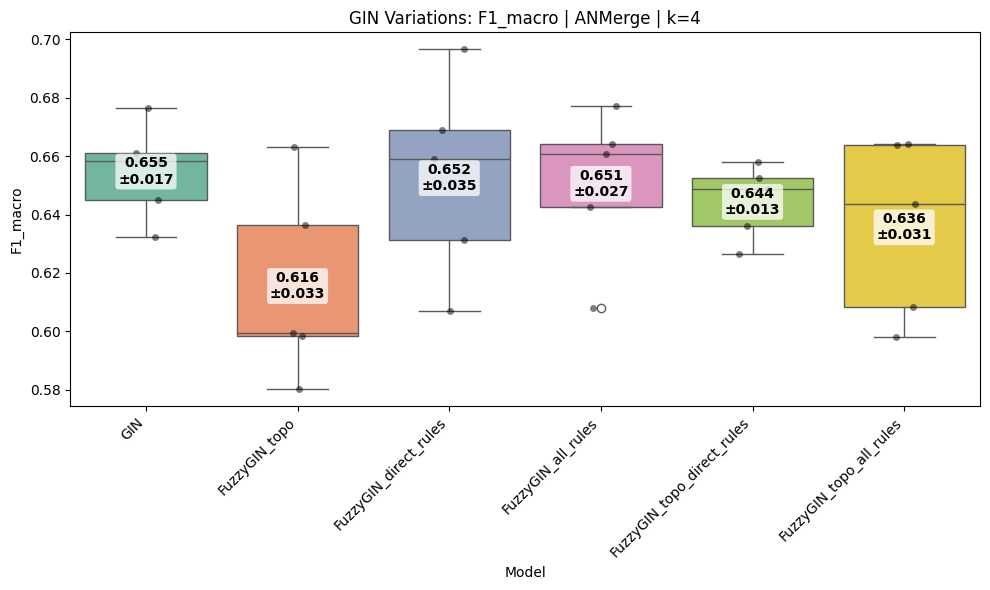

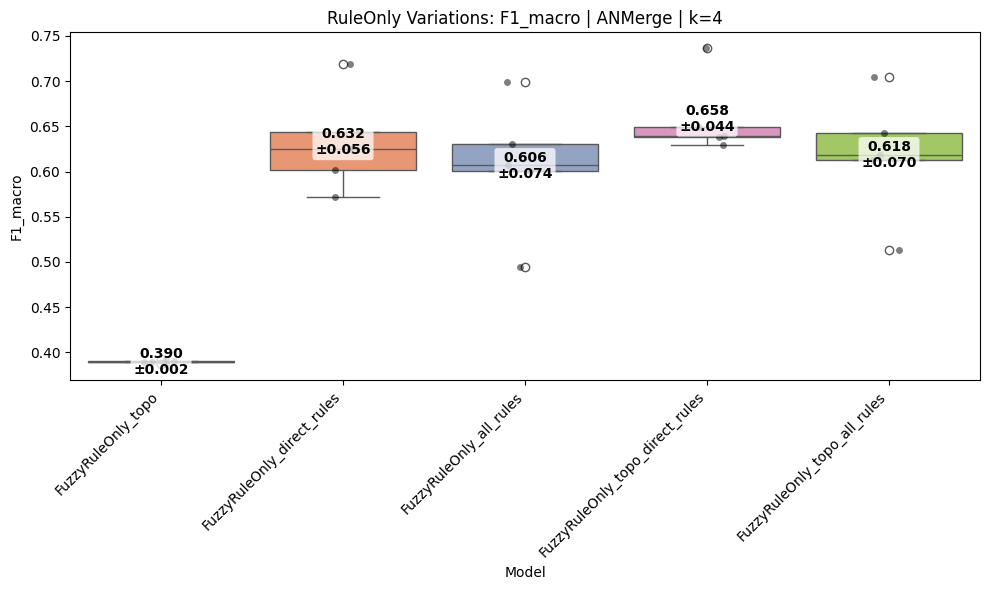

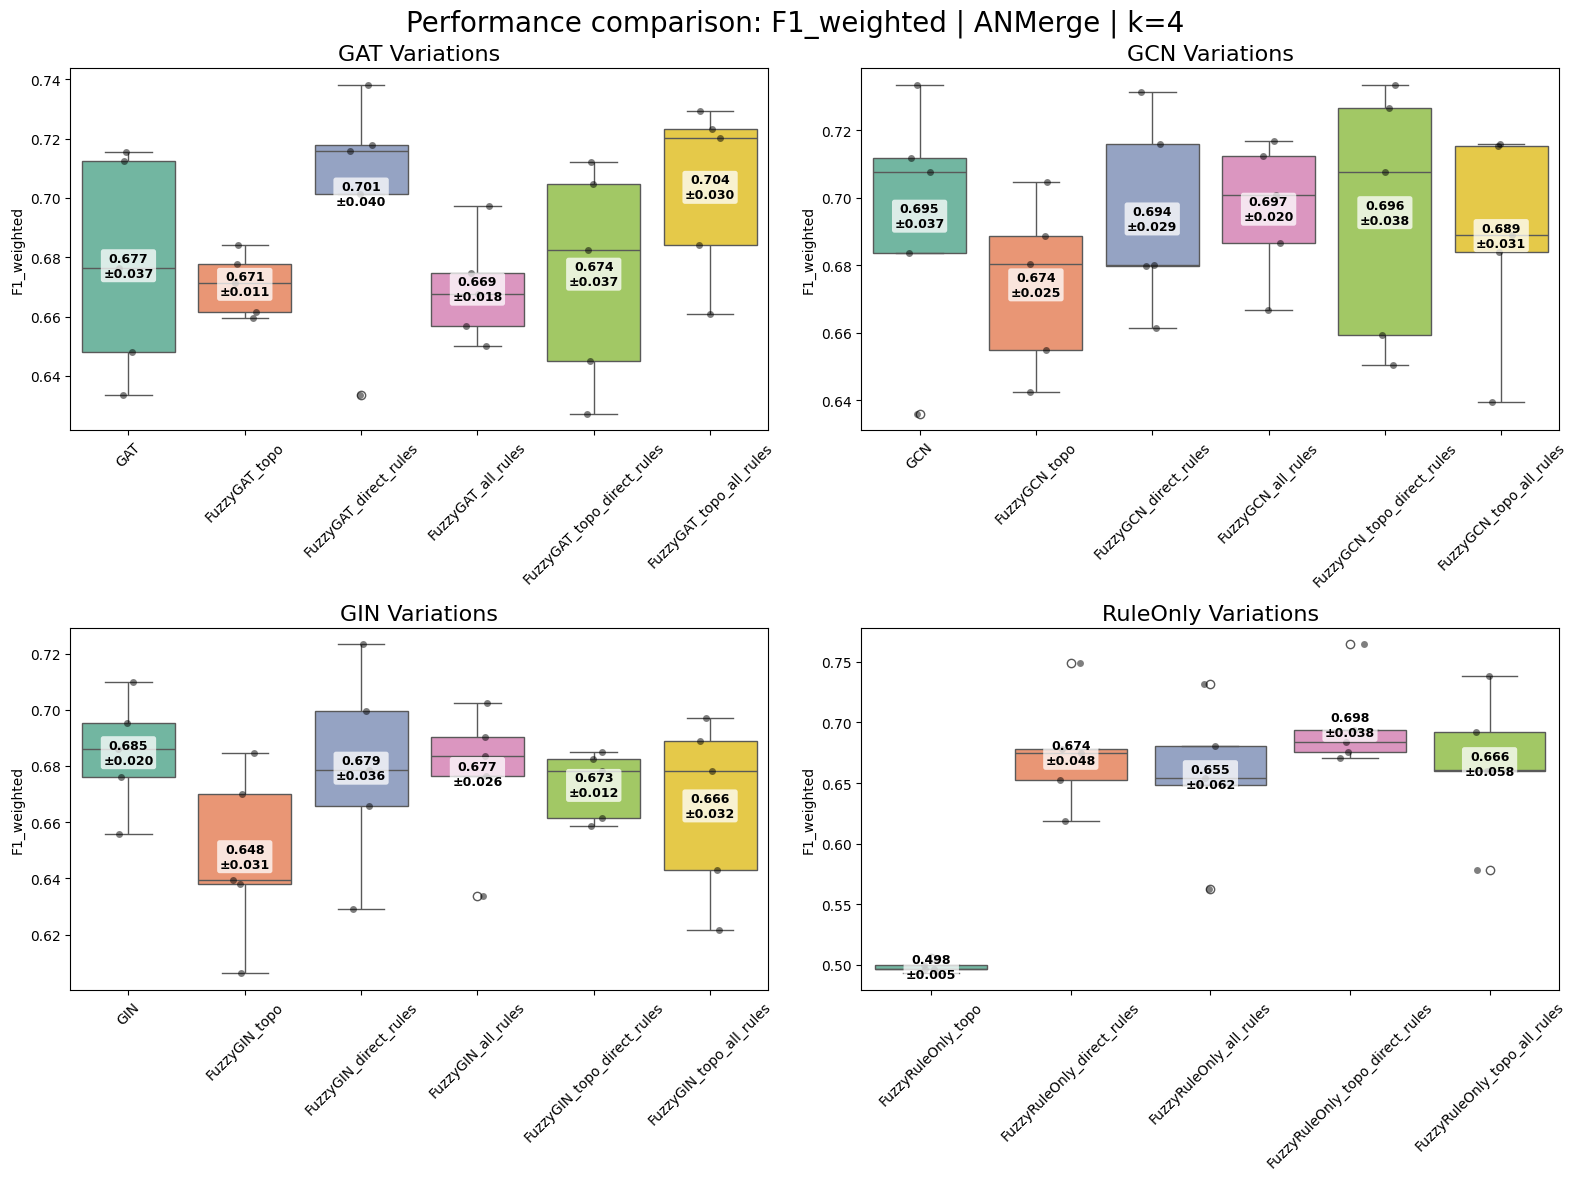

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GAT_ANMerge_k4_f1_weighted.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GCN_ANMerge_k4_f1_weighted.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GIN_ANMerge_k4_f1_weighted.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/RuleOnly_ANMerge_k4_f1_weighted.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_auroc.png


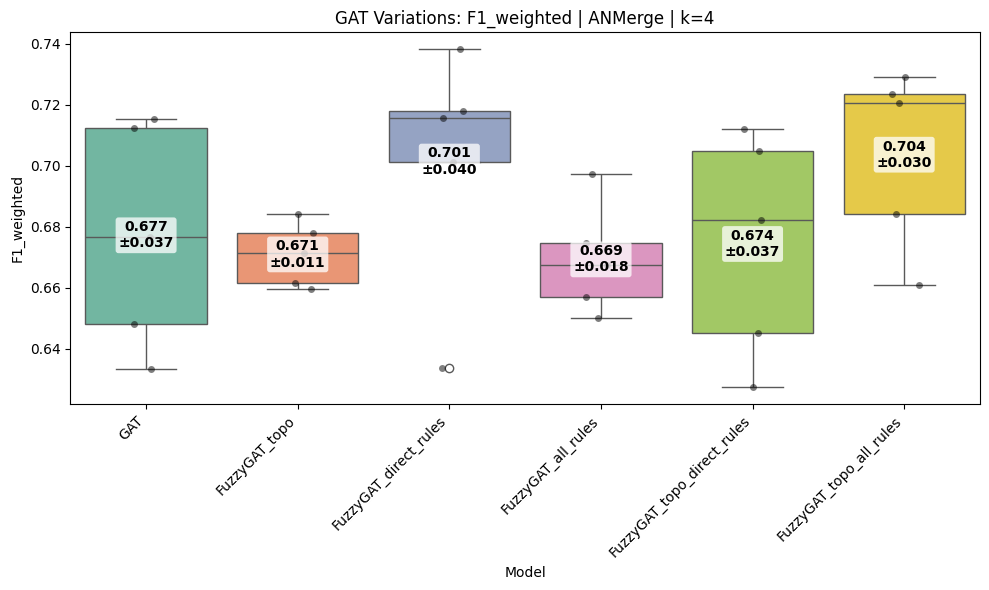

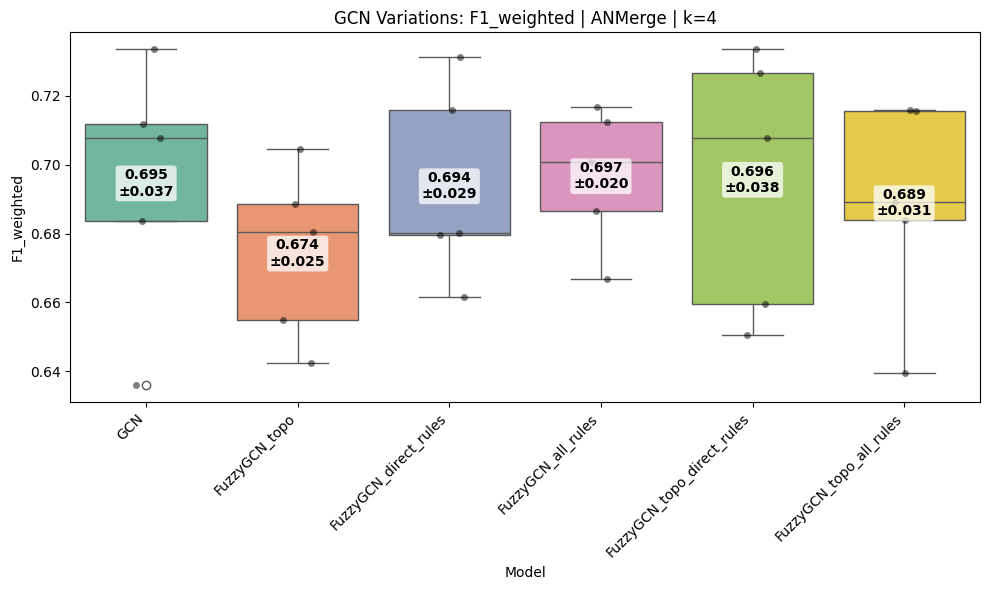

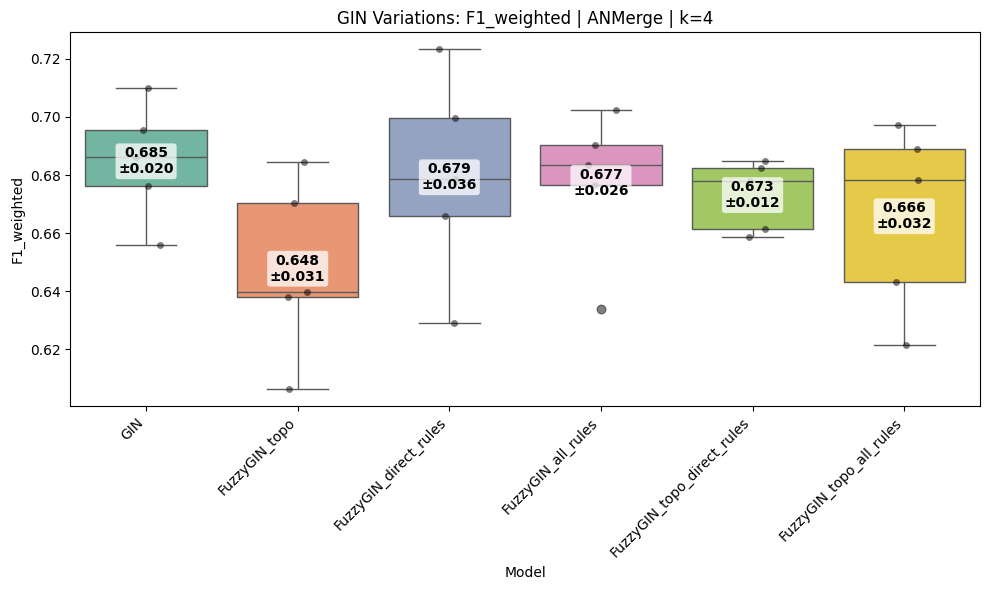

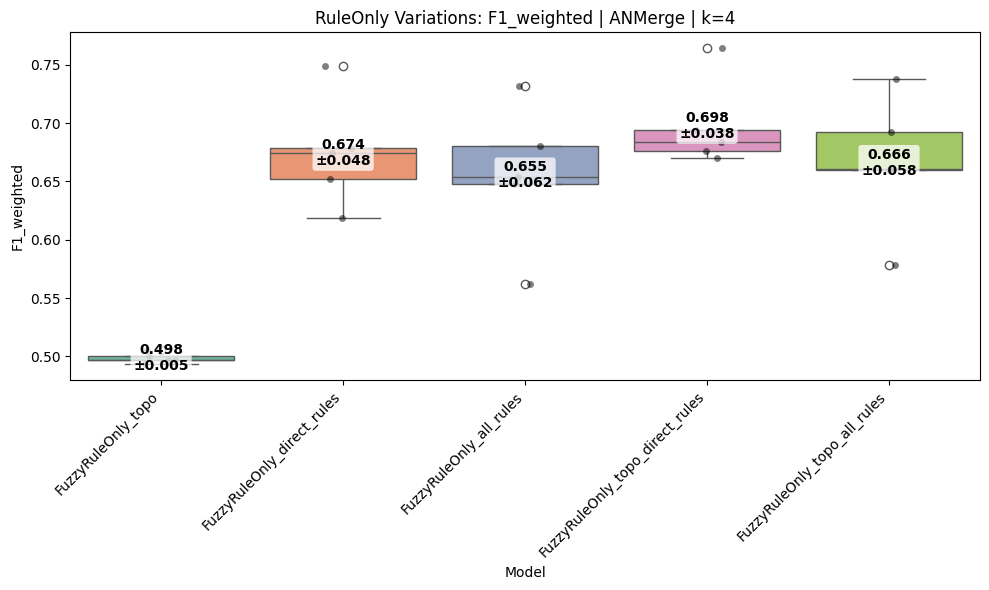

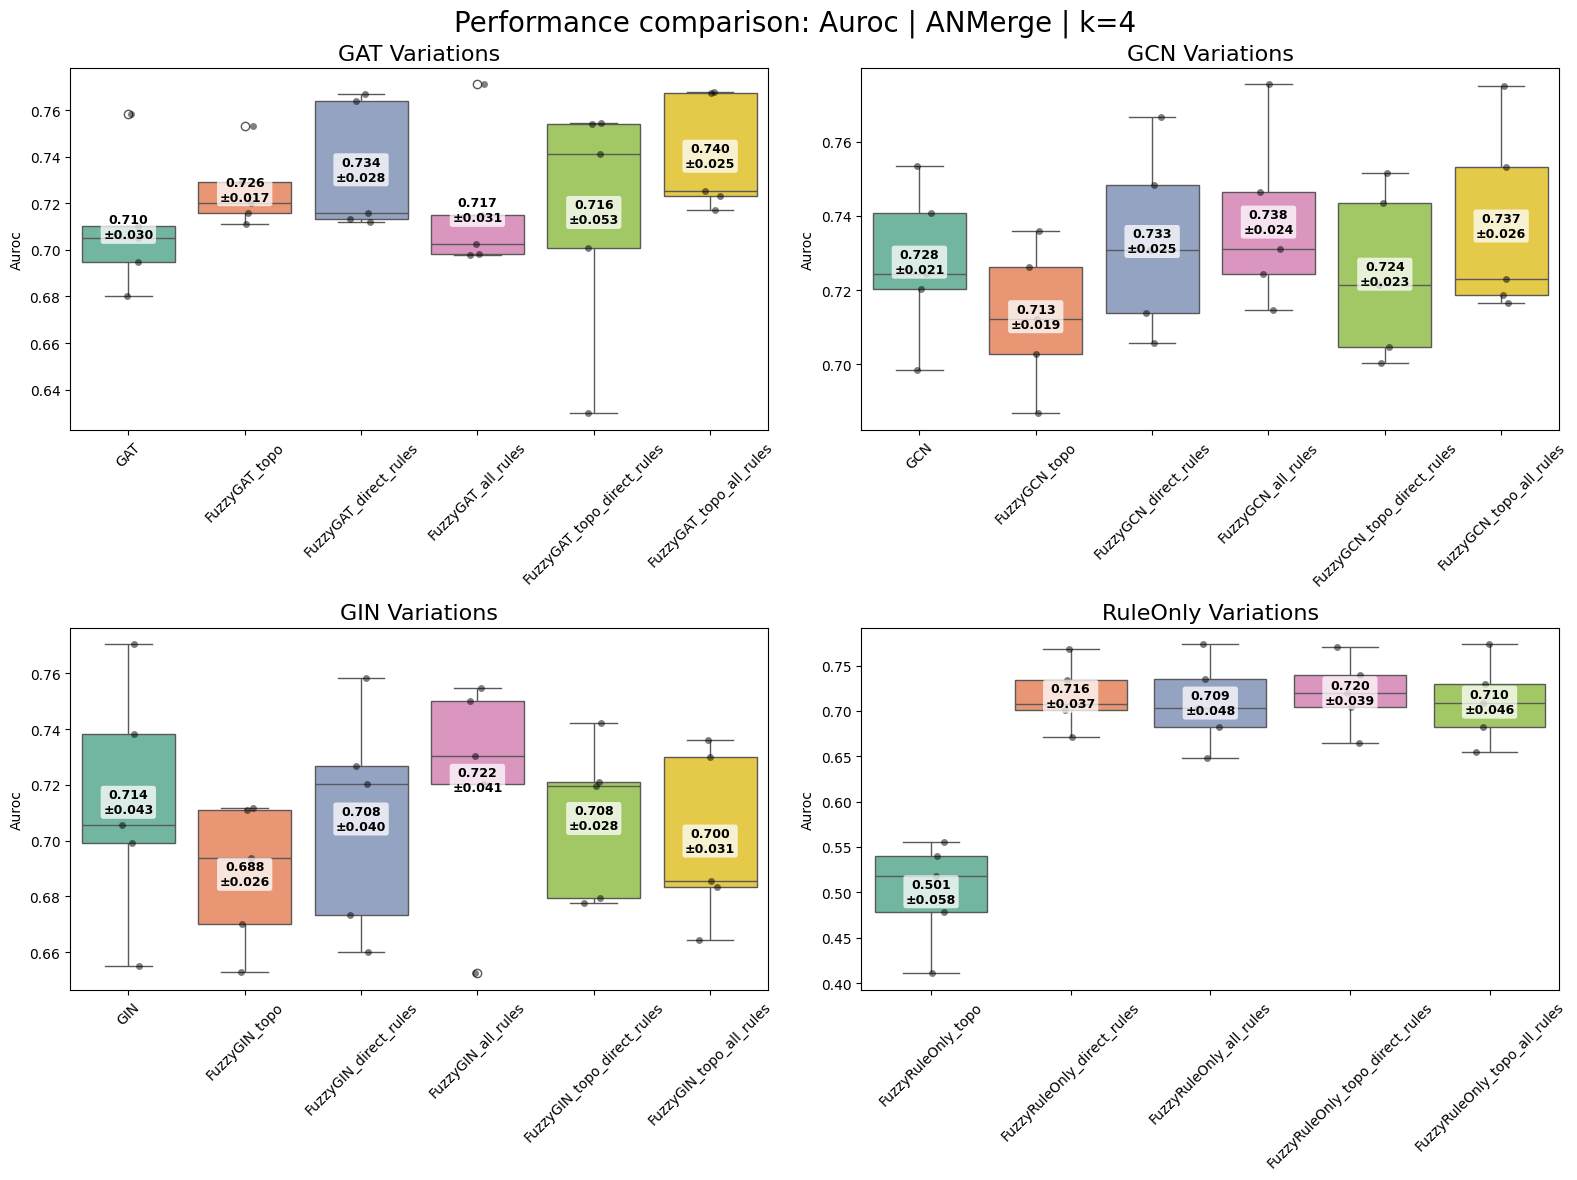

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GAT_ANMerge_k4_auroc.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GCN_ANMerge_k4_auroc.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GIN_ANMerge_k4_auroc.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/RuleOnly_ANMerge_k4_auroc.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_auprc.png


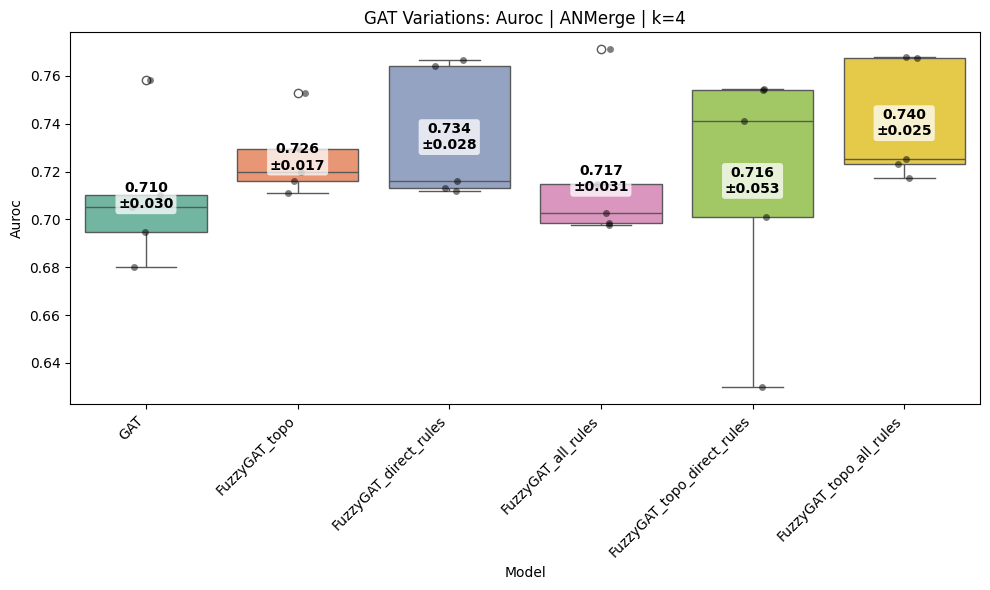

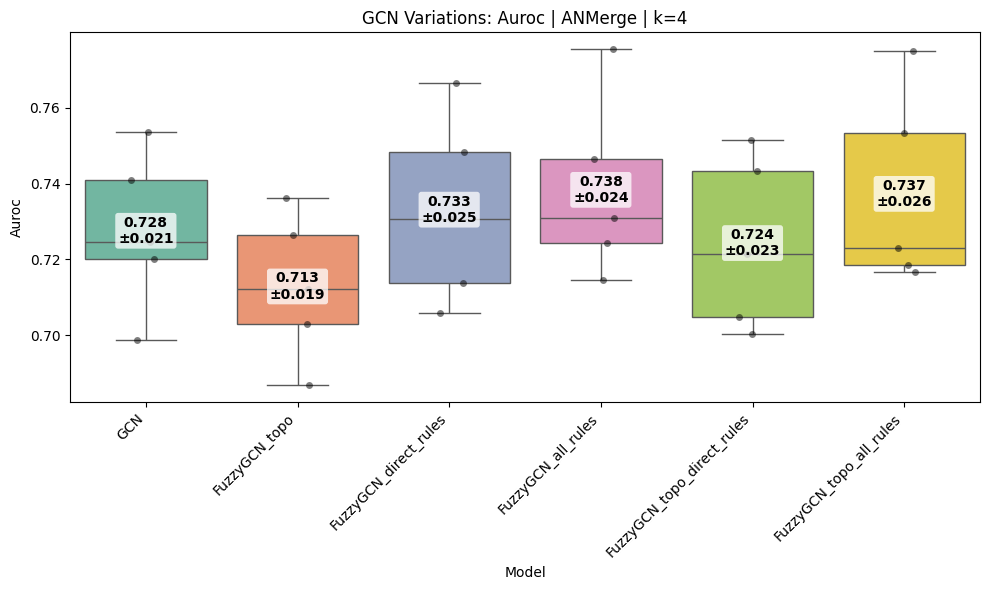

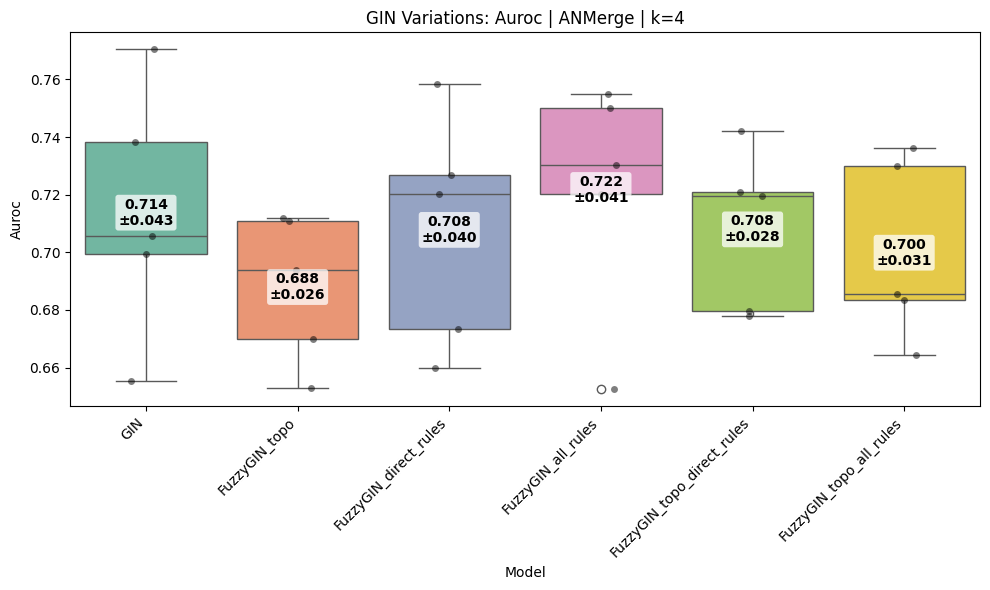

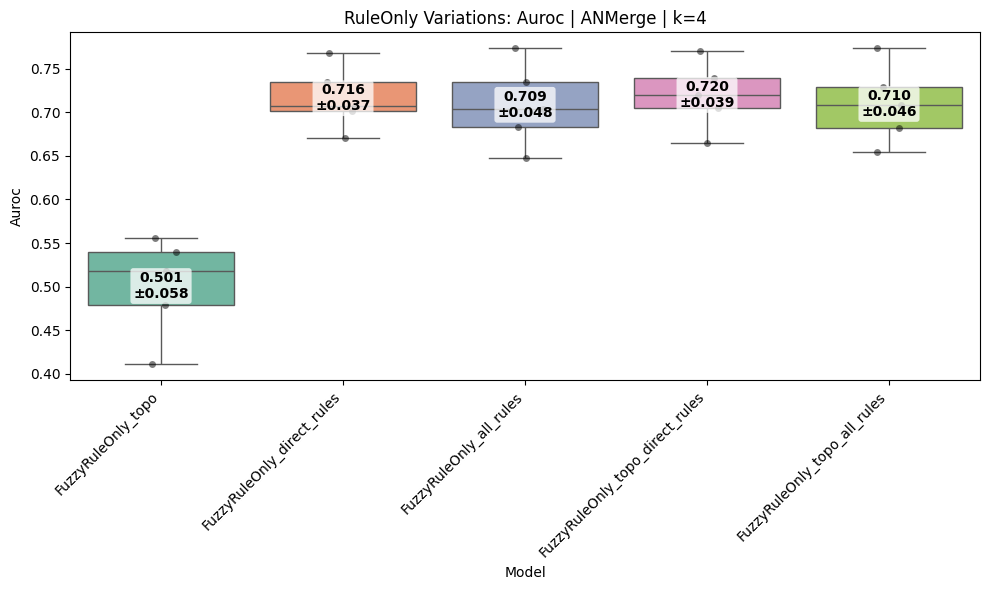

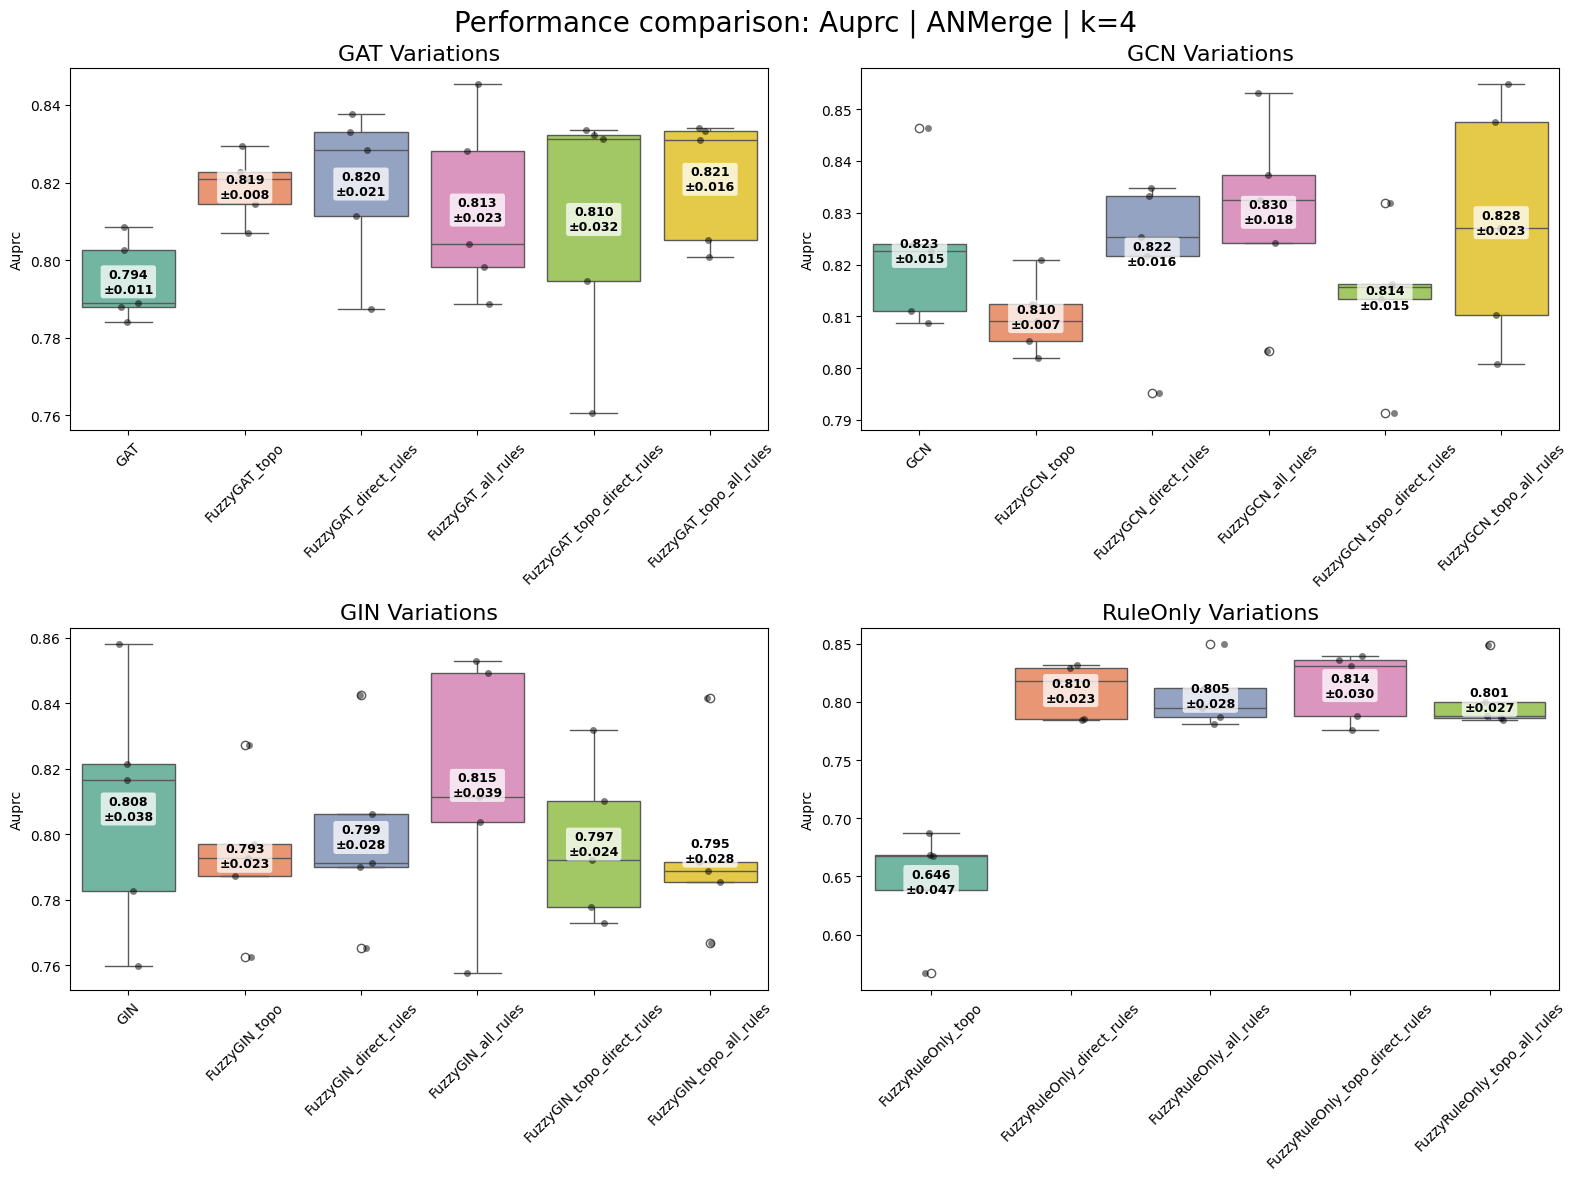

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GAT_ANMerge_k4_auprc.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GCN_ANMerge_k4_auprc.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/GIN_ANMerge_k4_auprc.png
Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/RuleOnly_ANMerge_k4_auprc.png


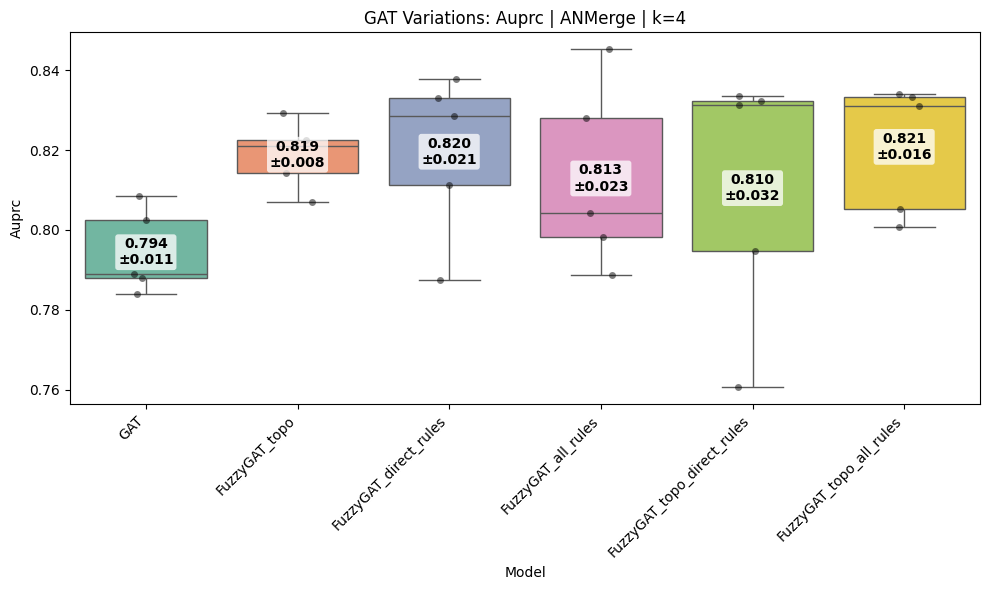

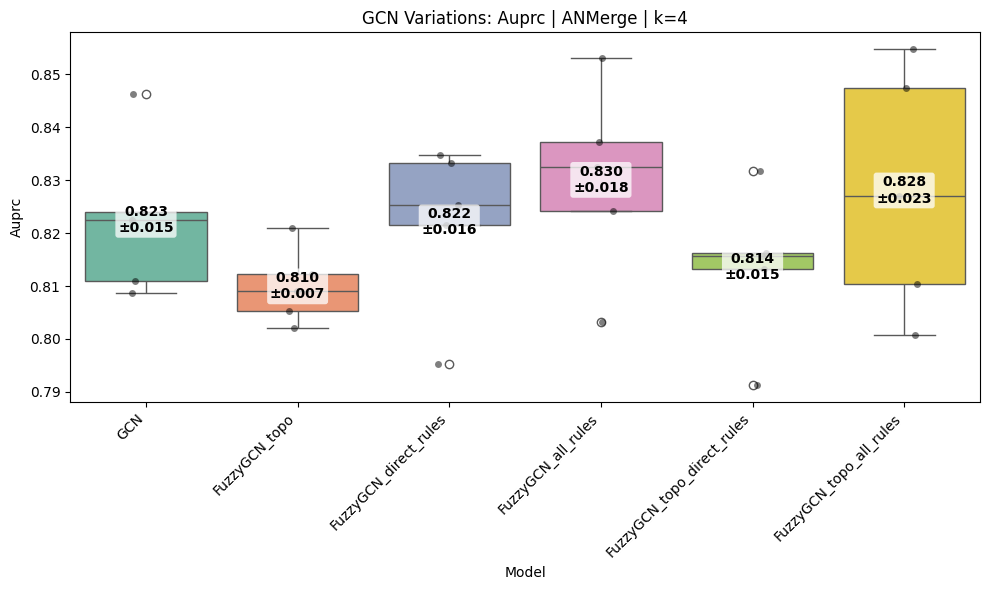

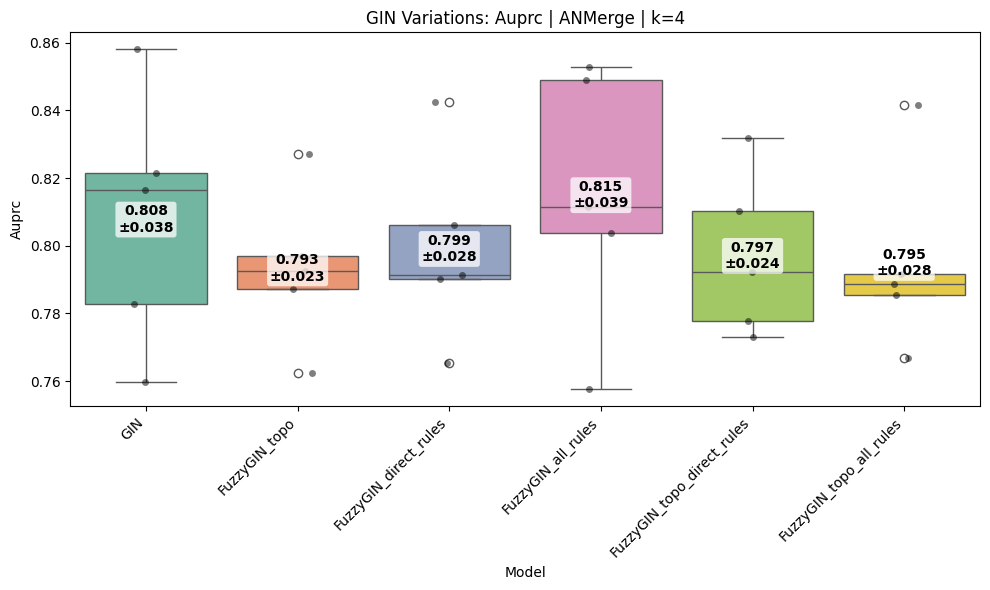

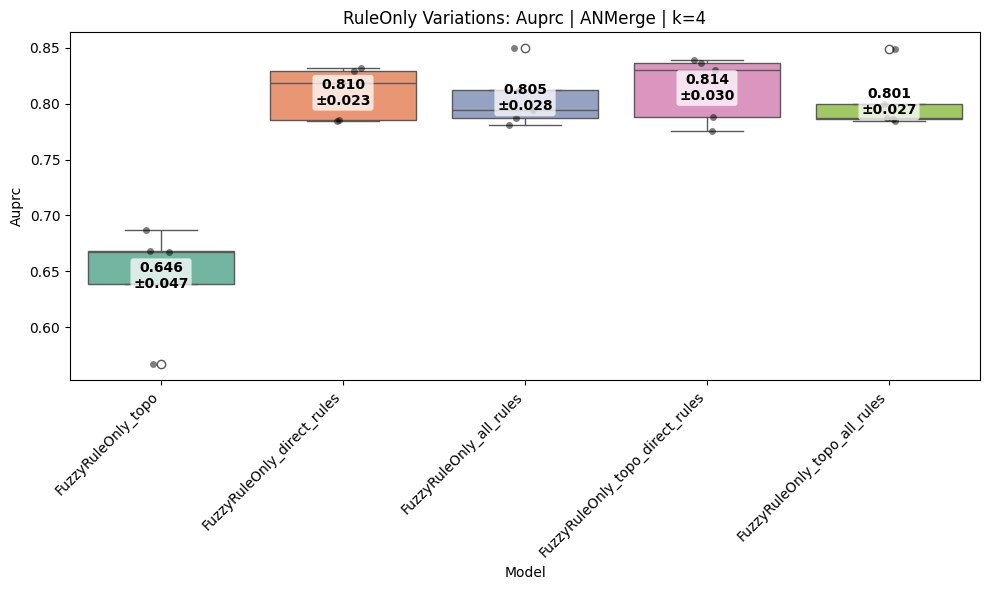

In [41]:
root_dir = "../nesy_gnn/results/explain/AD_KG"
save_plot = "../nesy_gnn/results/explain/AD_KG/metric_plots"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc'],
    var_name="metric",
    value_name="score",
)
dataset = 'ANMerge'
for metric in ['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc']:
    boxplot_all_backbones_subplots(df=df, metric_name=metric, dataset=dataset,k=4, output_dir=save_plot)
    for bb in ['GAT', 'GCN', 'GIN','RuleOnly']:
        boxplot_single_backbone(df=df,
                                metric_name=metric,
                                dataset=dataset,
                                target_backbone=bb,
                                k=4,
                                output_dir=save_plot)

## Compare same variation across all models

In [70]:
def variation_suffix(model):
    if "_" not in model:
        return "Baseline"
    else:
        suf = model.split("_")[1:]
        suffix = "_".join(suf)
        return suffix
    
# Compare the SAME variation across the 4 base models
def boxplot_single_variation(df, 
                                 metric_name: str, 
                                 dataset: str, 
                                 suffix: str, 
                                 k: str|int=4,
                                 output_dir=None):
    """
    Example usage: 
    If your models are named GCN_v1, GAT_v1, etc.
    Pass suffix="v1" to compare them.
    """
    plot_df = df[
        (df["metric"] == metric_name) & 
        (df["k"] == str(k))
    ].copy()

    plot_df["suffix"] = plot_df["model"].apply(variation_suffix)
    plot_df = plot_df[plot_df["suffix"] == suffix]
    target_models = sorted(plot_df['model'].unique())

    num_subplots = len(plot_df['suffix'].unique())
    fig, ax = plt.subplots(figsize=(10, 6))

    sns.boxplot(
        data=plot_df,
        x="model",
        y="score",
        ax=ax,
        # Order explicitly ensures they always appear in this specific order on the X-axis
        order=target_models, 
        palette="Set1"
    )
    # 2. Add data dots
    sns.stripplot(
        data=plot_df,
        x="model",
        y="score",
        color="black",
        alpha=0.5,
        jitter=True,
        size=5,
        ax=ax,
        order=target_models
    )
    
    # 3. Calculate and annotate Mean & Std inside boxes
    for idx, m in enumerate(target_models):
        scores = plot_df[plot_df["model"] == m]["score"]
        mean_val = scores.mean()
        std_val = scores.std()
        
        # Place text at the mean coordinate
        ax.text(
            idx, mean_val, 
            f"{mean_val:.3f}\n±{std_val:.3f}", 
            ha='center', va='center', 
            color='black', fontsize=10, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', boxstyle='round,pad=0.2')
        )

    plt.xticks(rotation=45, ha="right")
    plt.title(f"Variation Comparison ('{suffix}'): {metric_name.capitalize()} | {dataset} | k={k}")
    plt.ylabel(metric_name.capitalize())
    plt.xlabel("Model")
    plt.tight_layout()
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        filename = f"Variation_{suffix}_{dataset}_k{k}_{metric_name}.png"
        filepath = os.path.join(output_dir, filename)
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
        print(f"Saved plot to: {filepath}")
    plt.show()

def boxplot_all_variations(df, 
                            metric_name: str, 
                            dataset: str, 
                            k: str|int=4,
                            output_dir=None):
   
    plot_df = df[
        (df["metric"] == metric_name) & 
        (df["k"] == str(k))
    ].copy()

    plot_df["suffix"] = plot_df["model"].apply(variation_suffix)
    variations = plot_df['suffix'].unique()

    num_subplots = len(variations)
    fig, axs = plt.subplots(2, ceiling_div(num_subplots,2),figsize=(16, 12))
    axs = axs.flatten()
    
    for i, sfx in enumerate(variations):
        ax=axs[i]
        sfx_df = plot_df[plot_df["suffix"]==sfx]
        model_order= sorted(sfx_df['model'].unique())

        # 1. plot the boxes
        sns.boxplot(
            data=sfx_df,
            x="model",
            y="score",
            hue="model",
            legend=False,
            ax=ax,
            # Order explicitly ensures they always appear in this specific order on the X-axis
            order=model_order, 
            palette="Set1"
        )
        # 2. add data dots
        sns.stripplot(
            data=sfx_df,
            x="model",
            y="score",
            color="black",
            alpha=0.5,
            jitter=True,
            size=5,
            ax=ax,
            order=model_order
        )
        # 3. calculate and anotate Mean & Std inside boxes
        for idx, m in enumerate(model_order):
            scores = sfx_df[sfx_df['model']==m]['score']
            mean_val = scores.mean()
            std_val = scores.std()
            ax.text(
                idx, mean_val,
                f"{mean_val:.3f}\n±{std_val:.3f}",
                ha='center', va='center',
                color='black', fontsize=9, fontweight='bold',
                bbox=dict(facecolor='white', alpha=0.75, edgecolor='none',boxstyle='round,pad=0.2')
            )
        ax.set_title(f"{sfx} Variations", fontsize=16)
        ax.set_xlabel("")
        ax.set_ylabel(f"{metric_name.capitalize()}", fontsize=10)
        ax.tick_params(axis='x', rotation=45)

    # Remove any empty subplots (if num_subplots is odd)
    for j in range(num_subplots, len(axs)):
        fig.delaxes(axs[j])

    fig.suptitle(f"Variation Comparison across Models: {metric_name.capitalize()} | {dataset} | k={k}",fontsize=20)
    plt.tight_layout()

    if output_dir:
        os.makedirs(output_dir, exist_ok=True) 
        filename = f"all_variations_{dataset}_k{k}_{metric_name}.png"
        filepath = os.path.join(output_dir, filename)
        plt.savefig(filepath, dpi=300, bbox_inches='tight') # dpi=300 for high quality
        print(f"Saved plot to: {filepath}")
    plt.show()

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_variations_ANMerge_k4_accuracy.png


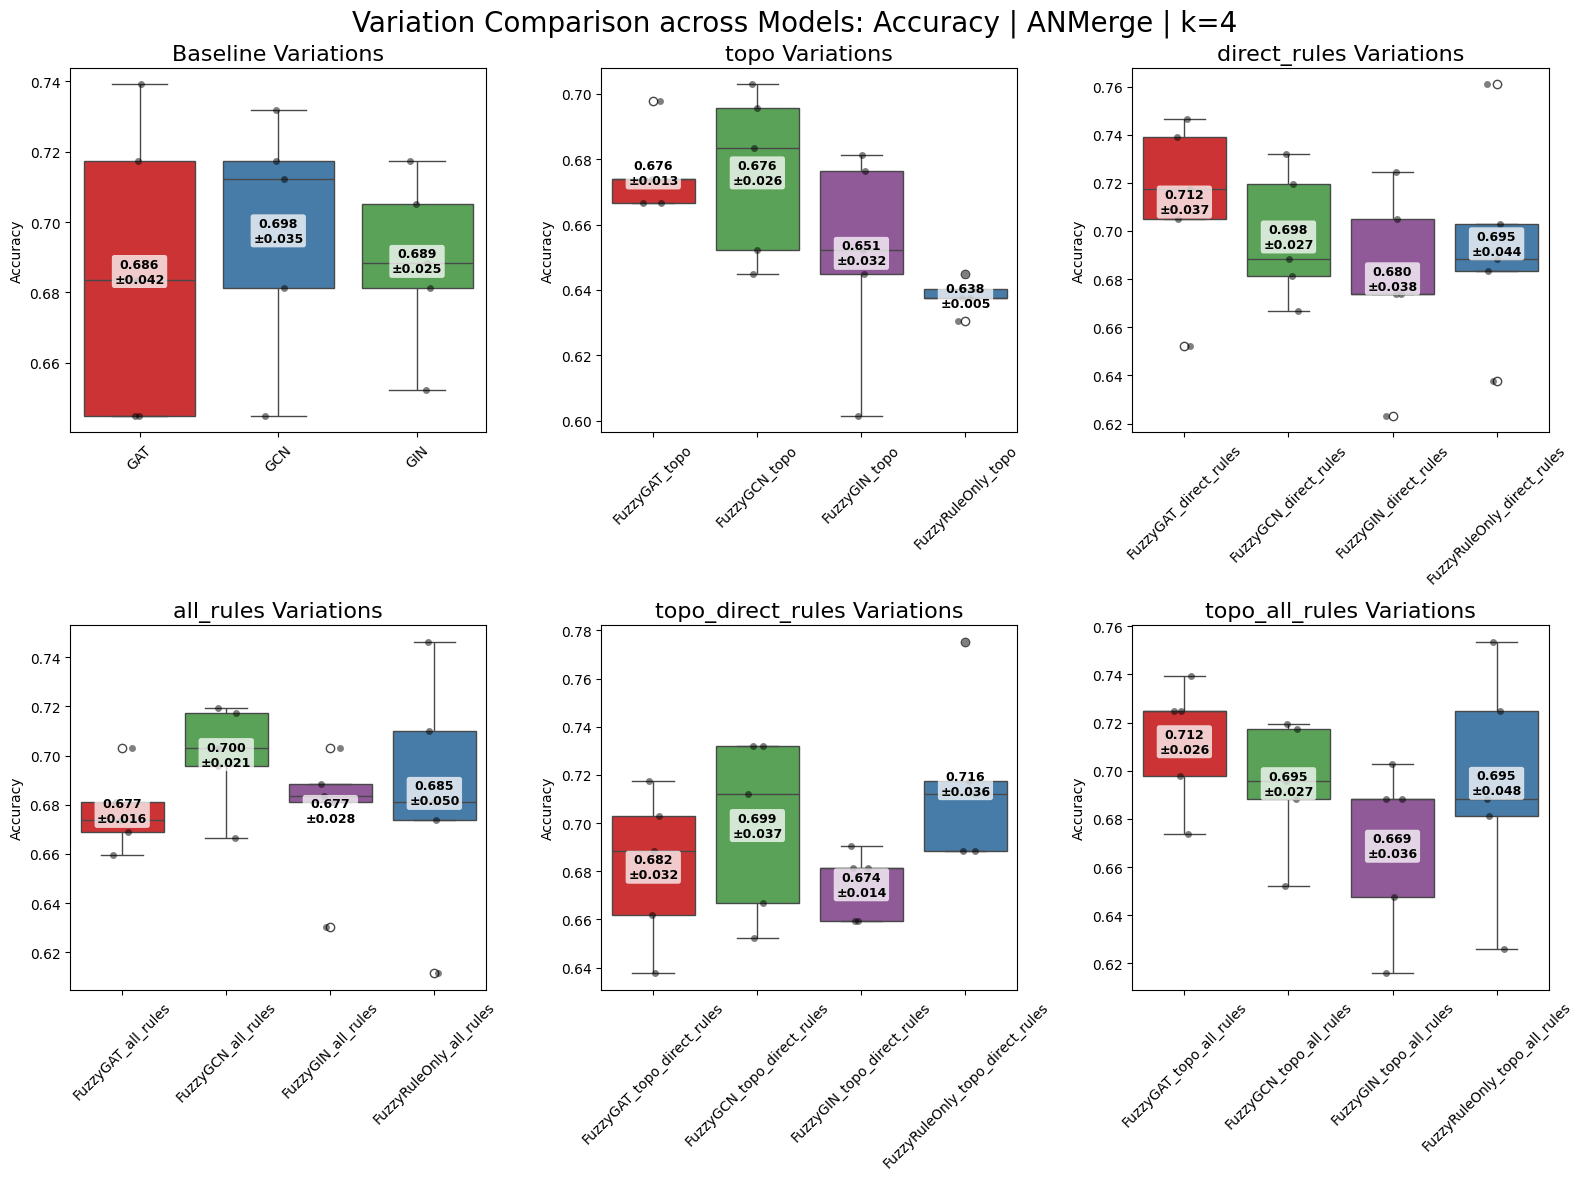

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_variations_ANMerge_k4_balanced_accuracy.png


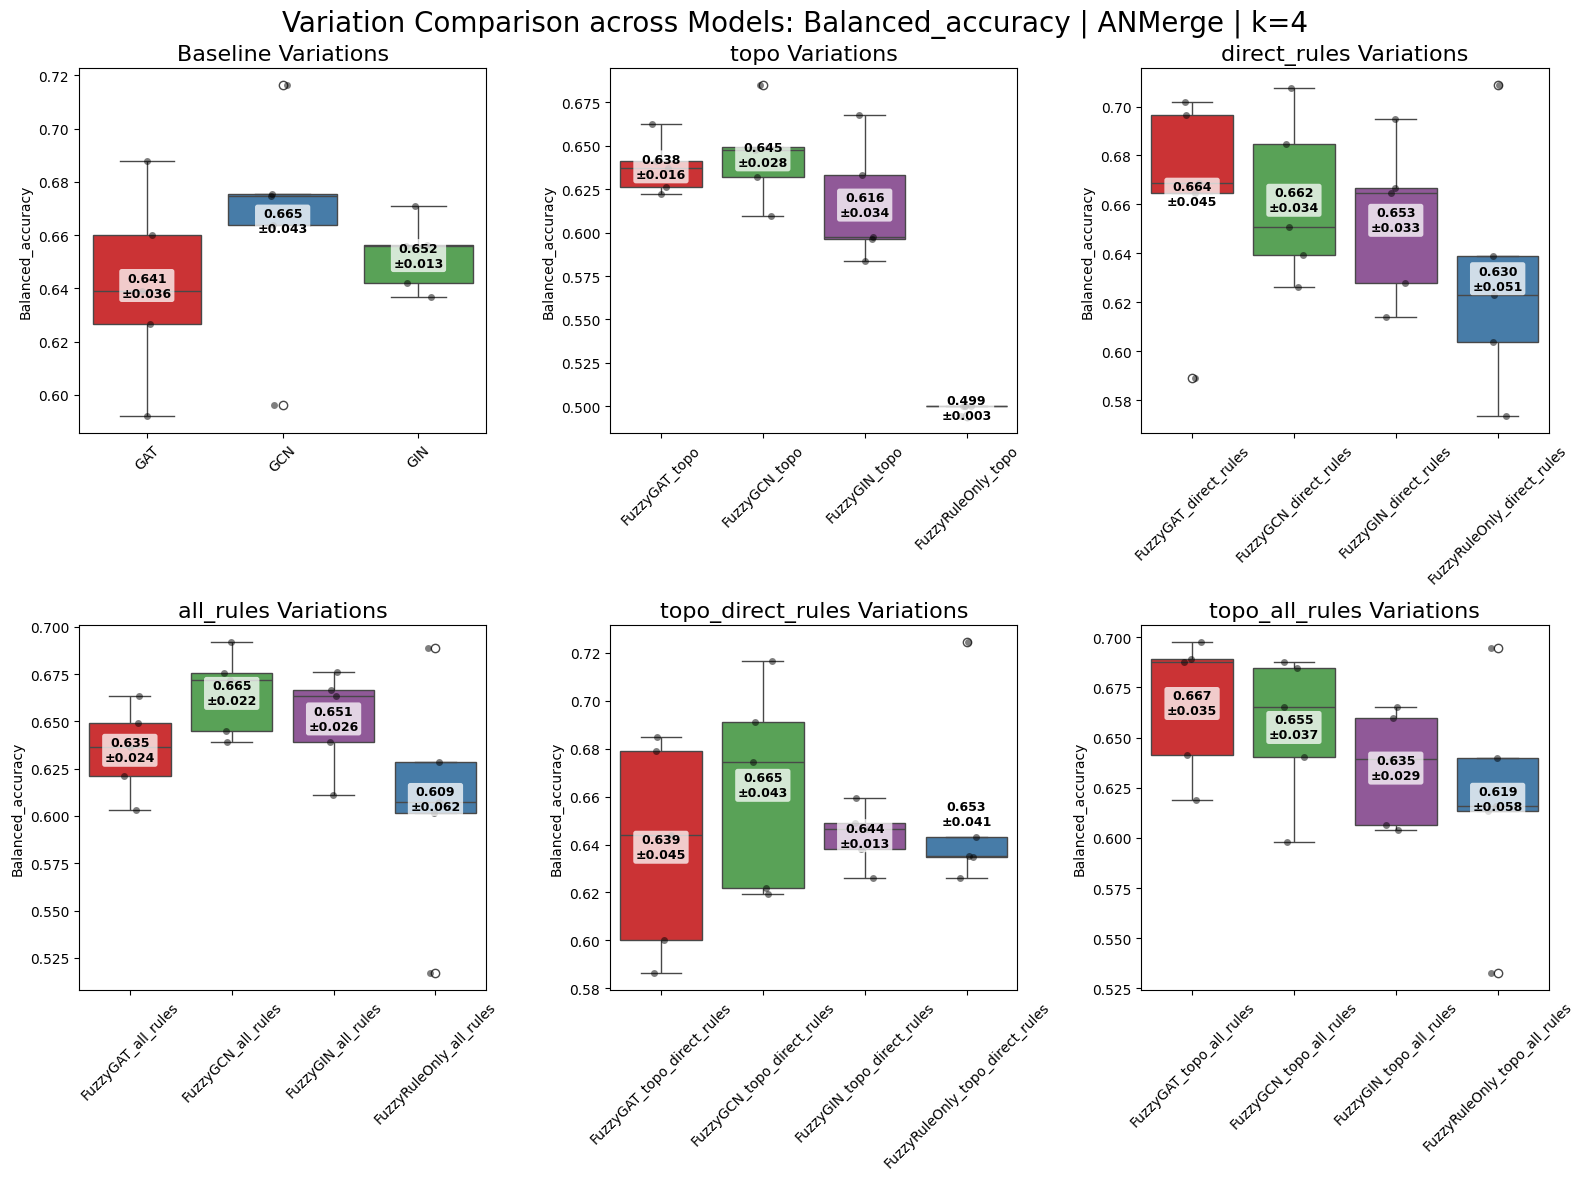

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_variations_ANMerge_k4_f1.png


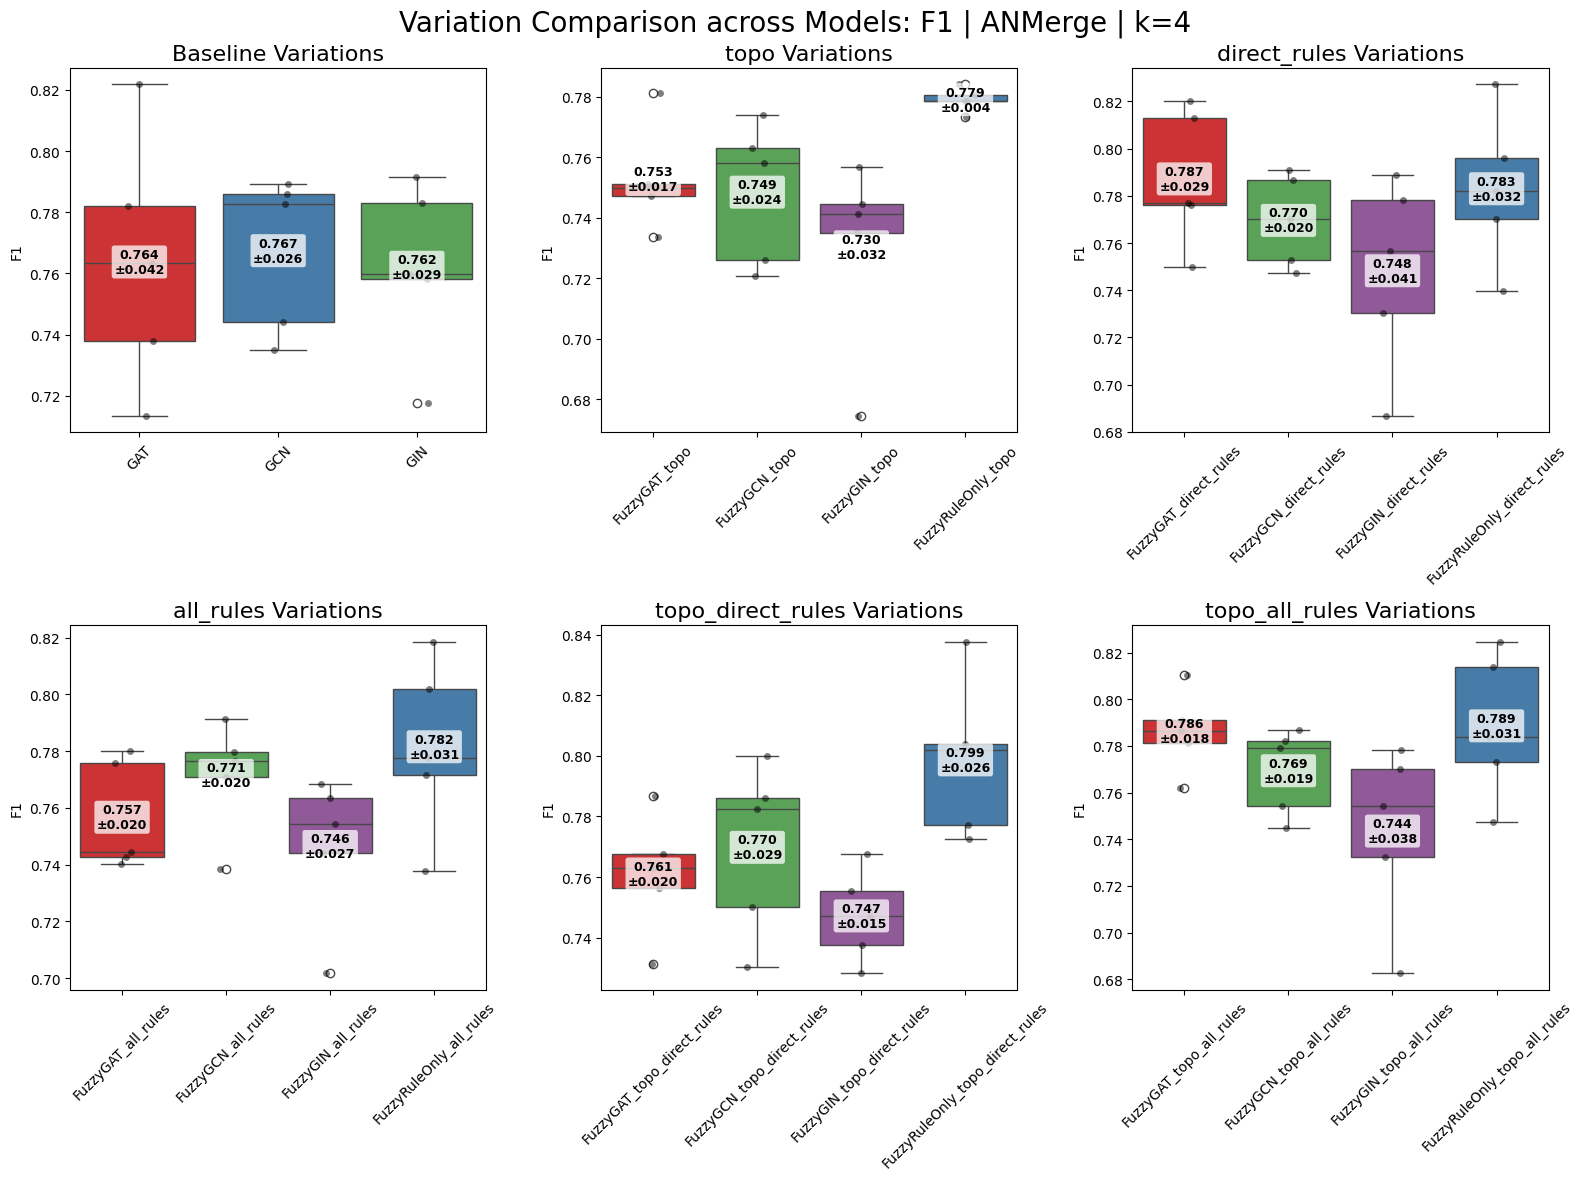

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_variations_ANMerge_k4_f1_macro.png


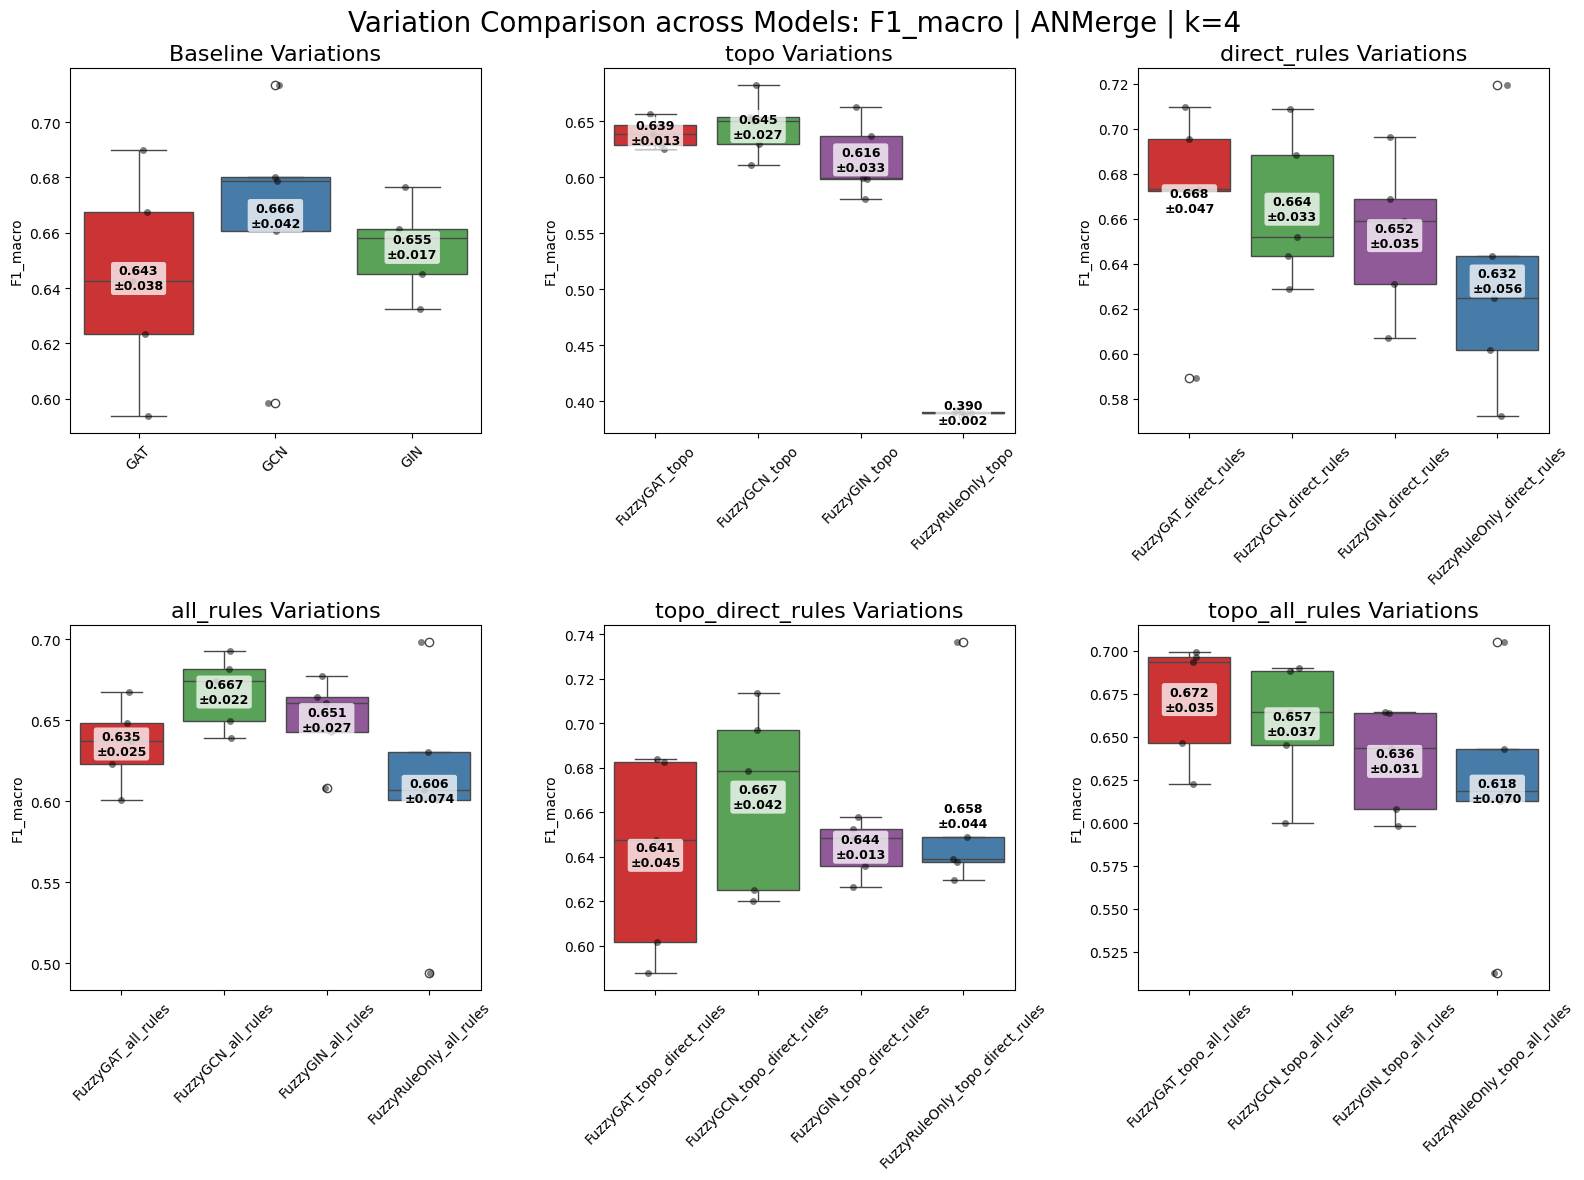

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_variations_ANMerge_k4_f1_weighted.png


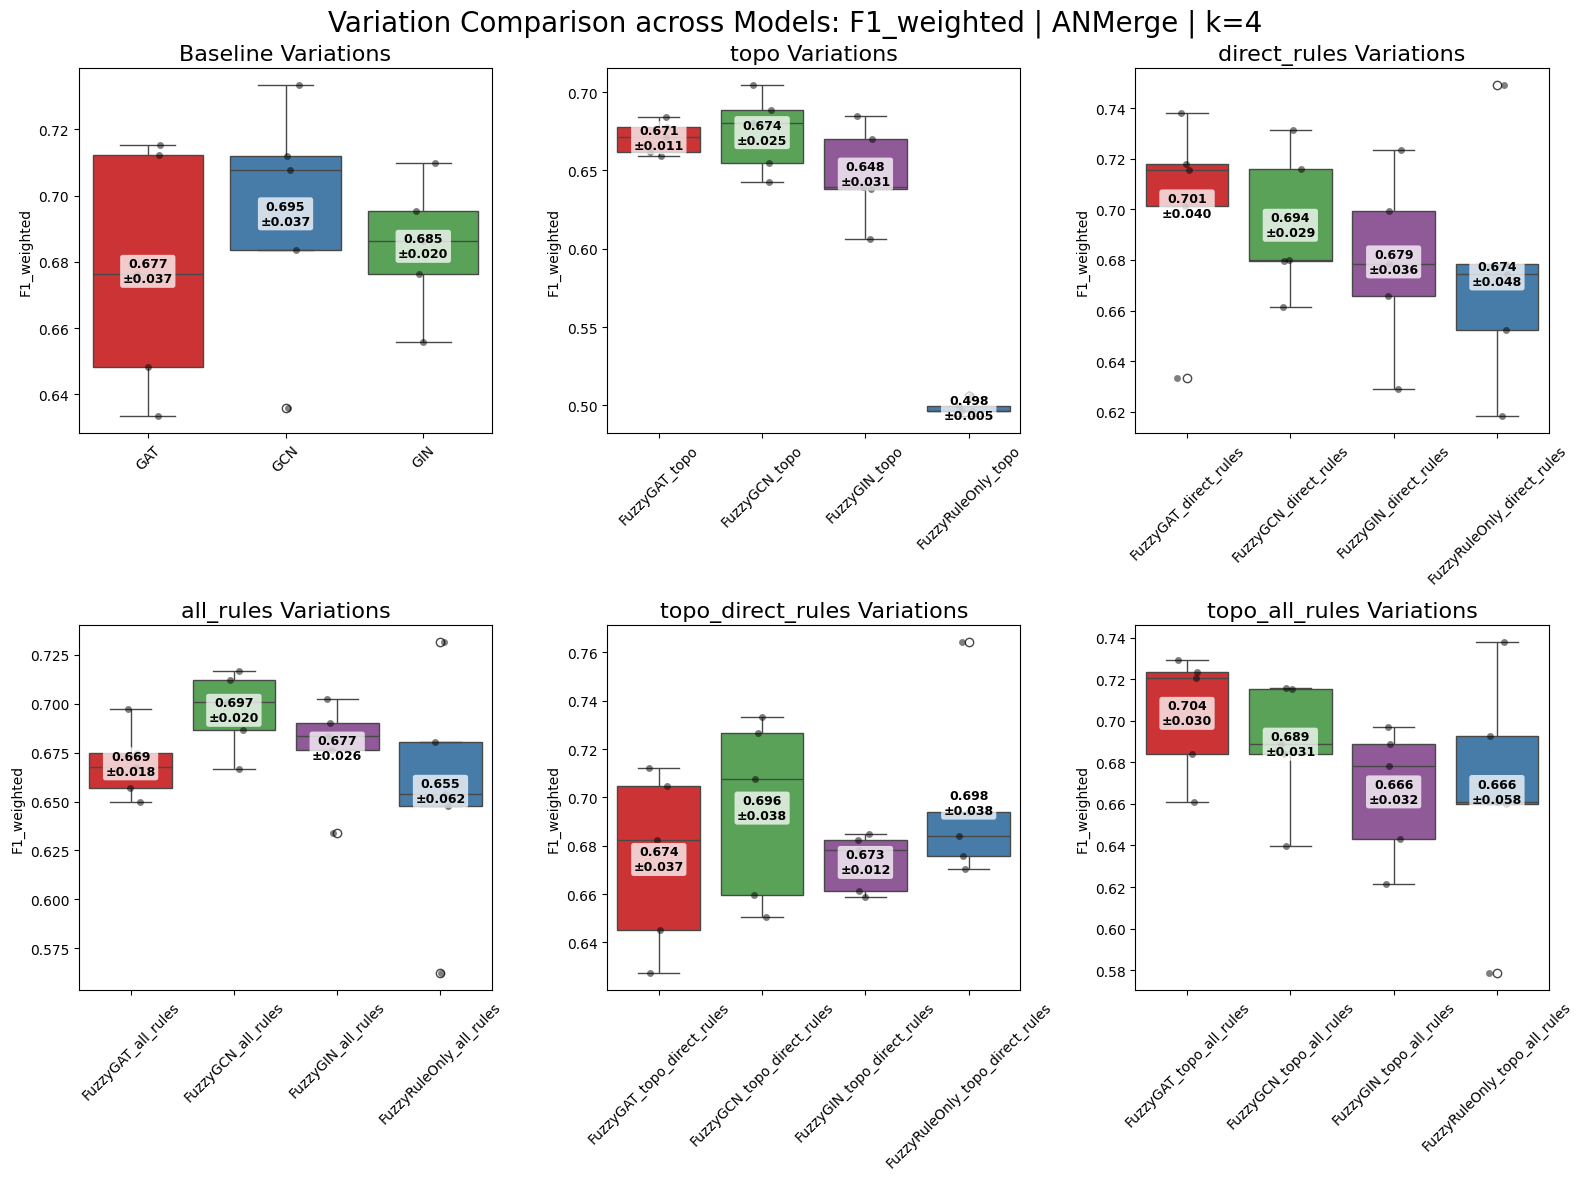

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_variations_ANMerge_k4_auroc.png


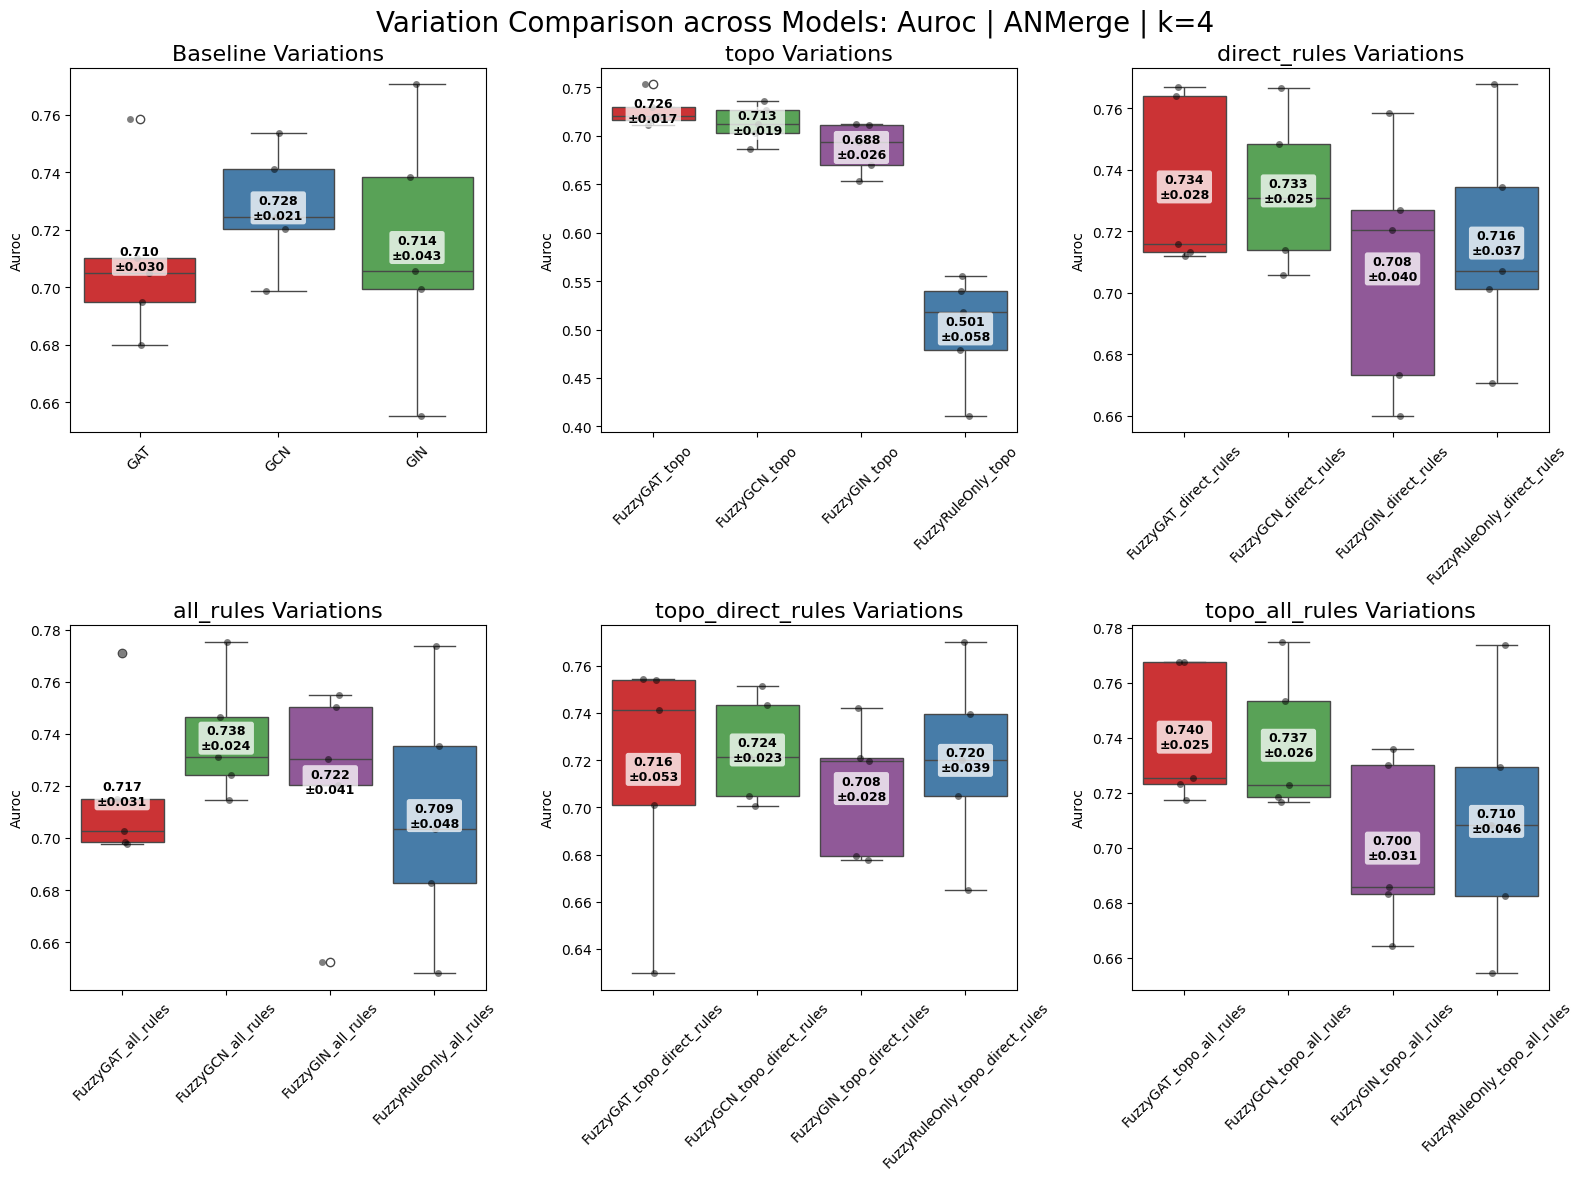

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_variations_ANMerge_k4_auprc.png


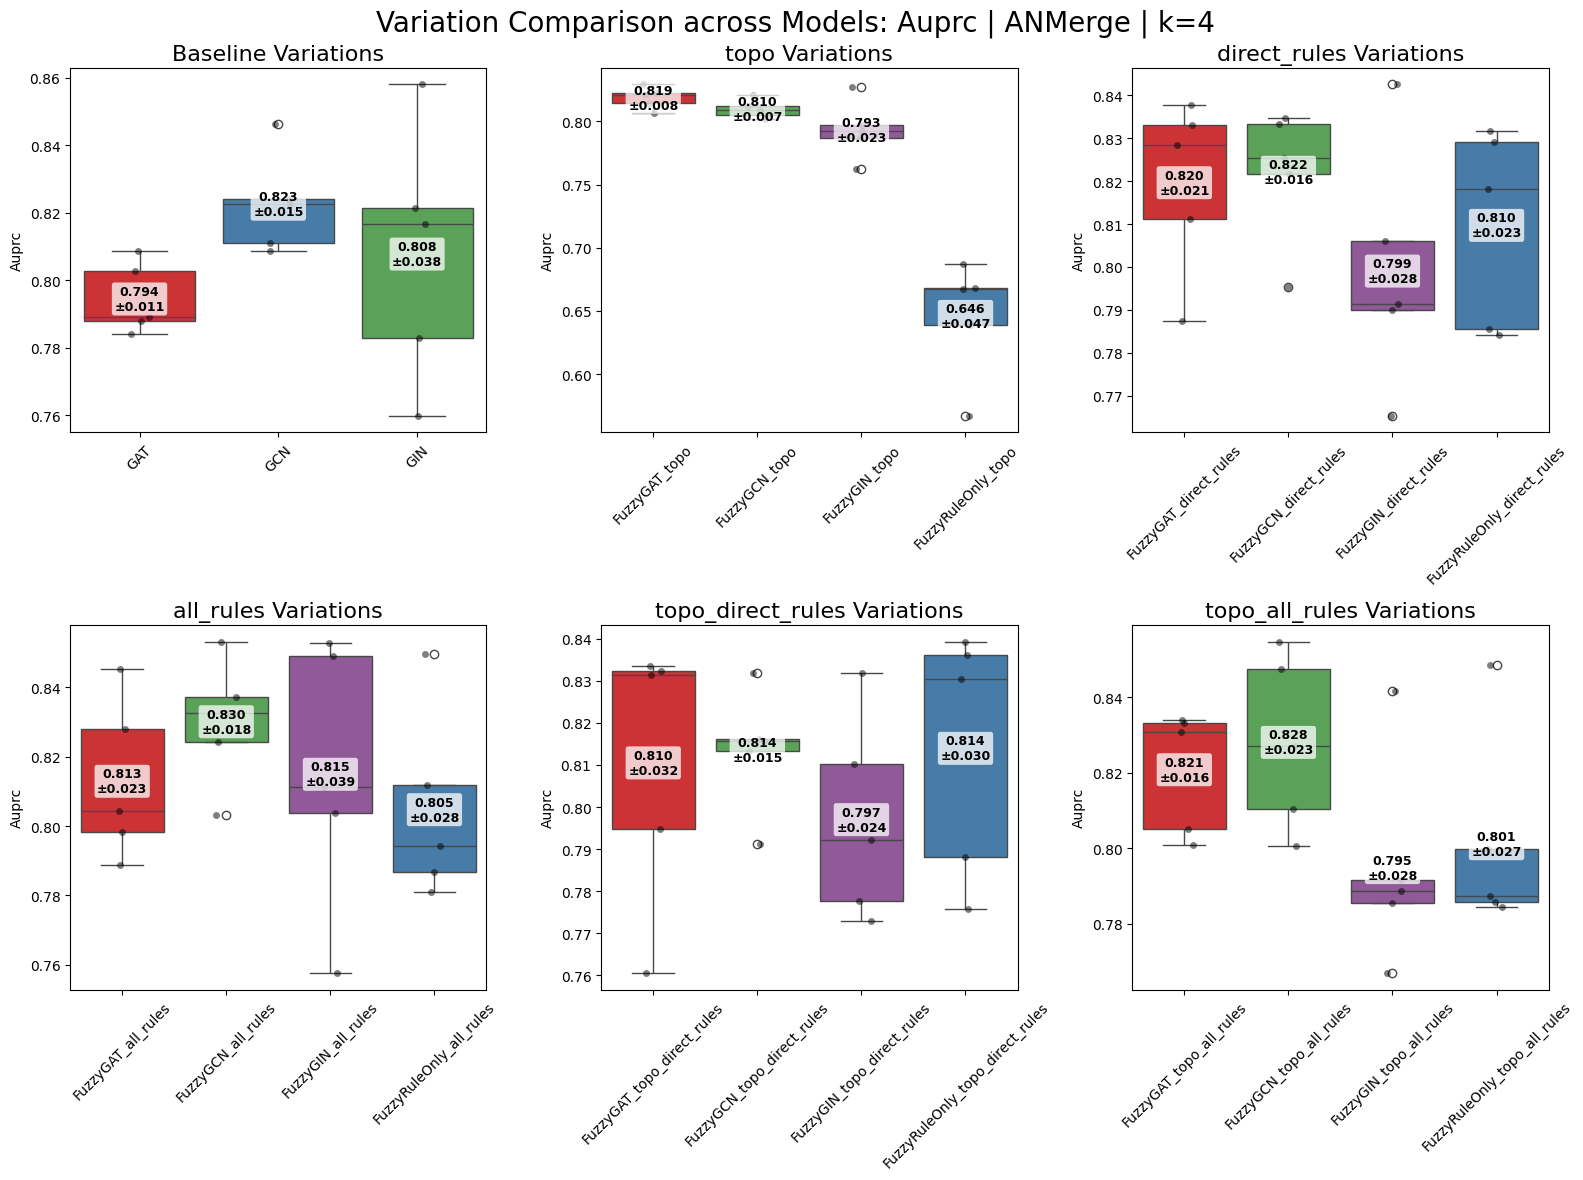

In [71]:
dataset = 'ANMerge'
for metric in ['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc']:
    boxplot_all_variations(df=df,
                           metric_name=metric,
                           dataset=dataset,
                           k=4,
                           output_dir=save_plot)
    # for sfx in ['Baseline', 'topo', 'direct_rules', 'all_rules', 'topo_direct_rules', 'topo_all_rules']:
    #     boxplot_single_variation(df=df,
    #                                  metric_name=metric,
    #                                  dataset=dataset,
    #                                  suffix=sfx,
    #                                  k=4)
    # break

In [49]:
plot_df = df[
        (df["metric"] == 'auroc') & 
        (df["k"] == str(4))
    ].copy()

plot_df["suffix"] = plot_df["model"].apply(variation_suffix)
#plot_df = plot_df[plot_df["suffix"] == 'topo']
plot_df['suffix'].unique()

<StringArray>
[         'Baseline',              'topo',      'direct_rules',
         'all_rules', 'topo_direct_rules',    'topo_all_rules']
Length: 6, dtype: str